# 🌾 AI-Based Crop Yield Prediction System
### Real crop records + soil nutrients (N, P, K, pH) + historical weather · 5-model comparison

The first prototype trained on **synthetic data generated from a formula**. This version is built entirely on **real data**:
19,689 crop records from Indian states, enriched with **soil nutrients** for every state and **year-by-year weather** fetched
from a public weather API. Five regression models are compared in one scikit-learn pipeline, the best one is tuned and explained,
and it powers a Gradio app.

## 📑 Contents  (click to jump)
1. [Data sources](#1.-Data-sources)
2. [Load the data](#2.-Load-the-data)
3. [Clean, merge and engineer features](#3.-Clean,-merge-and-engineer-features)
4. [Exploratory data analysis](#4.-Exploratory-data-analysis)
5. [Features, target and split](#5.-Features,-target-and-split)
6. [Preprocessing pipeline](#6.-Preprocessing-pipeline)
7. [**Train and compare 5 models**](#7.-Train-and-compare-5-models)
8. [Which data helps? (feature-group study)](#8.-Which-data-helps?-(feature-group-study))
9. [Tune the best model](#9.-Tune-the-best-model)
10. [Evaluate the final model](#10.-Evaluate-the-final-model)
11. [**Feature importance: what the Random Forest relies on**](#11.-Feature-importance:-what-the-Random-Forest-relies-on)
12. [Predicting future years](#12.-Predicting-future-years)
13. [Save the model](#13.-Save-the-model)
14. [Prediction function with a confidence range](#14.-Prediction-function-with-a-confidence-range)
15. [Gradio app](#15.-Gradio-app)
16. [Conclusion and model card](#16.-Conclusion-and-model-card)

## 0. Setup

In [ ]:
# Run once if a library is missing
%pip install -q numpy pandas scikit-learn matplotlib seaborn joblib gradio

In [2]:
import os, json, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

## 1. Data sources

| # | Data | What it adds | Source |
|---|---|---|---|
| 1 | **Crop yield records** (19,689 rows, 1997–2020) | Crop, season, state, year, area, production, annual rainfall, fertilizer, pesticide, **yield** | *Crop Yield in Indian States*, Kaggle (akshatgupta7); also Mendeley Data, DOI 10.17632/ncw2vbcgnk.2 |
| 2 | **Soil profile per state** (30 states) | **Nitrogen (N), Phosphorus (P), Potassium (K)** and **soil pH** | State soil table from *Crop Yield Data with Soil and Weather*, Kaggle (anshumish) |
| 3 | **Weather per state per year** (1997–2020) | **Average temperature, maximum temperature, relative humidity, solar radiation** | **Open-Meteo Historical Weather API** (ERA5 reanalysis), fetched for a central point in each state |

All three are joined on **State** (and **Year** for weather), so every crop record gets the soil and the weather of its state and year.

## 2. Load the data

In [3]:
crop = pd.read_csv("data/crop_yield.csv")
soil = pd.read_csv("data/state_soil.csv")
print("Crop records:", crop.shape, "| Soil table:", soil.shape)
crop.head()

Crop records: (19689, 10) | Soil table: (30, 5)


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [4]:
soil.head(10)

,State,N,P,K,pH
0,Andhra Pradesh,78,45,22,6.8
1,Arunachal Pradesh,55,15,35,5.5
2,Assam,60,18,38,5.8
3,Bihar,85,30,25,7.2
4,Chhattisgarh,70,35,20,6.5
5,Delhi,90,40,30,7.5
6,Goa,65,25,45,6.2
7,Gujarat,75,38,28,7.8
8,Haryana,130,48,35,7.9
9,Himachal Pradesh,60,20,40,6.0


### Weather from the Open-Meteo API
The function below shows how the weather table was built: for each state it calls the **Open-Meteo Historical Weather API**
(ERA5 reanalysis) for 1997–2020 and averages the daily values per year. The result is saved to `data/state_weather.csv`,
so the API is only called when that file is missing (the free API allows a few large requests per minute).

In [5]:
STATE_COORDS = {  # approximate central point of each state / UT (latitude, longitude)
    "Andhra Pradesh": (15.9, 79.7), "Arunachal Pradesh": (28.2, 94.7), "Assam": (26.2, 92.9), "Bihar": (25.7, 85.6),
    "Chhattisgarh": (21.3, 81.9), "Delhi": (28.65, 77.2), "Goa": (15.35, 74.0), "Gujarat": (22.4, 71.4),
    "Haryana": (29.1, 76.1), "Himachal Pradesh": (31.9, 77.2), "Jammu and Kashmir": (33.3, 75.2), "Jharkhand": (23.6, 85.3),
    "Karnataka": (15.0, 75.7), "Kerala": (10.4, 76.4), "Madhya Pradesh": (23.5, 78.5), "Maharashtra": (19.4, 76.1),
    "Manipur": (24.7, 93.9), "Meghalaya": (25.5, 91.4), "Mizoram": (23.4, 92.8), "Nagaland": (26.1, 94.5),
    "Odisha": (20.5, 84.4), "Puducherry": (11.93, 79.8), "Punjab": (30.9, 75.6), "Sikkim": (27.5, 88.5),
    "Tamil Nadu": (11.0, 78.4), "Telangana": (17.9, 79.0), "Tripura": (23.8, 91.6), "Uttar Pradesh": (26.9, 80.9),
    "Uttarakhand": (30.1, 79.0), "West Bengal": (23.0, 87.8),
}

def fetch_state_weather(state, lat, lon, start=1997, end=2020):
    url = ("https://archive-api.open-meteo.com/v1/archive"
           f"?latitude={lat}&longitude={lon}&start_date={start}-01-01&end_date={end}-12-31"
           "&daily=temperature_2m_mean,temperature_2m_max,relative_humidity_2m_mean,shortwave_radiation_sum"
           "&timezone=Asia%2FKolkata")
    with urllib.request.urlopen(url, timeout=120) as r:
        daily = pd.DataFrame(json.load(r)["daily"])
    daily["Crop_Year"] = daily["time"].str[:4].astype(int)
    yearly = daily.groupby("Crop_Year").agg(
        Avg_Temp_C=("temperature_2m_mean", "mean"), Max_Temp_C=("temperature_2m_max", "mean"),
        Humidity_pct=("relative_humidity_2m_mean", "mean"), Solar_Radiation_MJ=("shortwave_radiation_sum", "mean"),
    ).round(2).reset_index()
    yearly.insert(0, "State", state)
    return yearly

WEATHER_PATH = "data/state_weather.csv"
if not os.path.exists(WEATHER_PATH):
    frames = []
    for st, (lat, lon) in STATE_COORDS.items():
        frames.append(fetch_state_weather(st, lat, lon)); print("fetched", st)
        time.sleep(35)                       # stay inside the free API's per-minute limit
    pd.concat(frames).to_csv(WEATHER_PATH, index=False)

weather = pd.read_csv(WEATHER_PATH)
print("Weather table:", weather.shape, "->", weather["State"].nunique(), "states x", weather["Crop_Year"].nunique(), "years")
weather.head()

Weather table: (720, 6) -> 30 states x 24 years


,State,Crop_Year,Avg_Temp_C,Max_Temp_C,Humidity_pct,Solar_Radiation_MJ
0,Andhra Pradesh,1997,28.07,33.42,66.07,19.04
1,Andhra Pradesh,1998,28.07,33.22,68.68,18.72
2,Andhra Pradesh,1999,27.85,33.39,64.18,19.43
3,Andhra Pradesh,2000,27.24,32.47,69.33,18.94
4,Andhra Pradesh,2001,27.89,33.22,65.77,18.98


## 3. Clean, merge and engineer features
* Strip stray spaces from text columns (the raw file has values like `'Kharif     '`).
* Join soil (by State) and weather (by State + Year) onto every crop record.
* **Engineered features:** `Fertilizer_per_ha` and `Pesticide_per_ha` turn the raw totals into rates, so they no longer just repeat the farm size.
* **`Production` is never used as an input**: Yield = Production ÷ Area, so it would leak the answer.
* Yield is extremely skewed (coconut is counted in nuts), so the models learn **log(1 + Yield)** and predictions are converted back.

In [6]:
for col in ["Crop", "Season", "State"]:
    crop[col] = crop[col].str.strip()
crop = crop.drop_duplicates().reset_index(drop=True)

df = (crop.merge(soil, on="State", how="left")
          .merge(weather, on=["State", "Crop_Year"], how="left"))
df["Fertilizer_per_ha"] = df["Fertilizer"] / df["Area"]
df["Pesticide_per_ha"] = df["Pesticide"] / df["Area"]

print("Merged shape:", df.shape)
print("Missing values after merge:", int(df.isnull().sum().sum()))
print("Crops:", df["Crop"].nunique(), "| States:", df["State"].nunique(), "| Seasons:", df["Season"].nunique(),
      "| Years:", df["Crop_Year"].min(), "-", df["Crop_Year"].max())
df.head()

Merged shape: (19689, 20)
Missing values after merge: 0
Crops: 55 | States: 30 | Seasons: 6 | Years: 1997 - 2020


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,N,P,K,pH,Avg_Temp_C,Max_Temp_C,Humidity_pct,Solar_Radiation_MJ,Fertilizer_per_ha,Pesticide_per_ha
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,60,18,38,5.8,21.61,25.97,81.99,15.85,95.17,0.31
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,60,18,38,5.8,21.61,25.97,81.99,15.85,95.17,0.31
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,60,18,38,5.8,21.61,25.97,81.99,15.85,95.17,0.31
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,60,18,38,5.8,21.61,25.97,81.99,15.85,95.17,0.31
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,60,18,38,5.8,21.61,25.97,81.99,15.85,95.17,0.31


In [7]:
df[["Area", "Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha", "N", "P", "K", "pH",
    "Avg_Temp_C", "Max_Temp_C", "Humidity_pct", "Solar_Radiation_MJ", "Yield"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Area,19689.0,179926.57,732828.68,0.50,1390.00,9317.00,75112.00,50808100.00
Annual_Rainfall,19689.0,1437.76,816.91,301.30,940.70,1247.60,1643.70,6552.70
Fertilizer_per_ha,19689.0,137.16,26.20,94.67,108.34,144.49,157.91,193.61
Pesticide_per_ha,19689.0,0.27,0.07,0.09,0.22,0.27,0.33,0.38
N,19689.0,76.63,20.06,50.00,65.00,72.00,80.00,150.00
P,19689.0,33.50,11.56,15.00,24.00,38.00,43.00,55.00
K,19689.0,32.23,7.92,20.00,25.00,33.00,38.00,50.00
pH,19689.0,6.64,0.69,5.50,6.00,6.60,7.10,8.00
Avg_Temp_C,19689.0,23.40,4.97,8.47,22.45,25.31,26.47,29.48
Max_Temp_C,19689.0,28.50,5.20,13.60,26.82,30.56,31.57,35.49


## 4. Exploratory data analysis

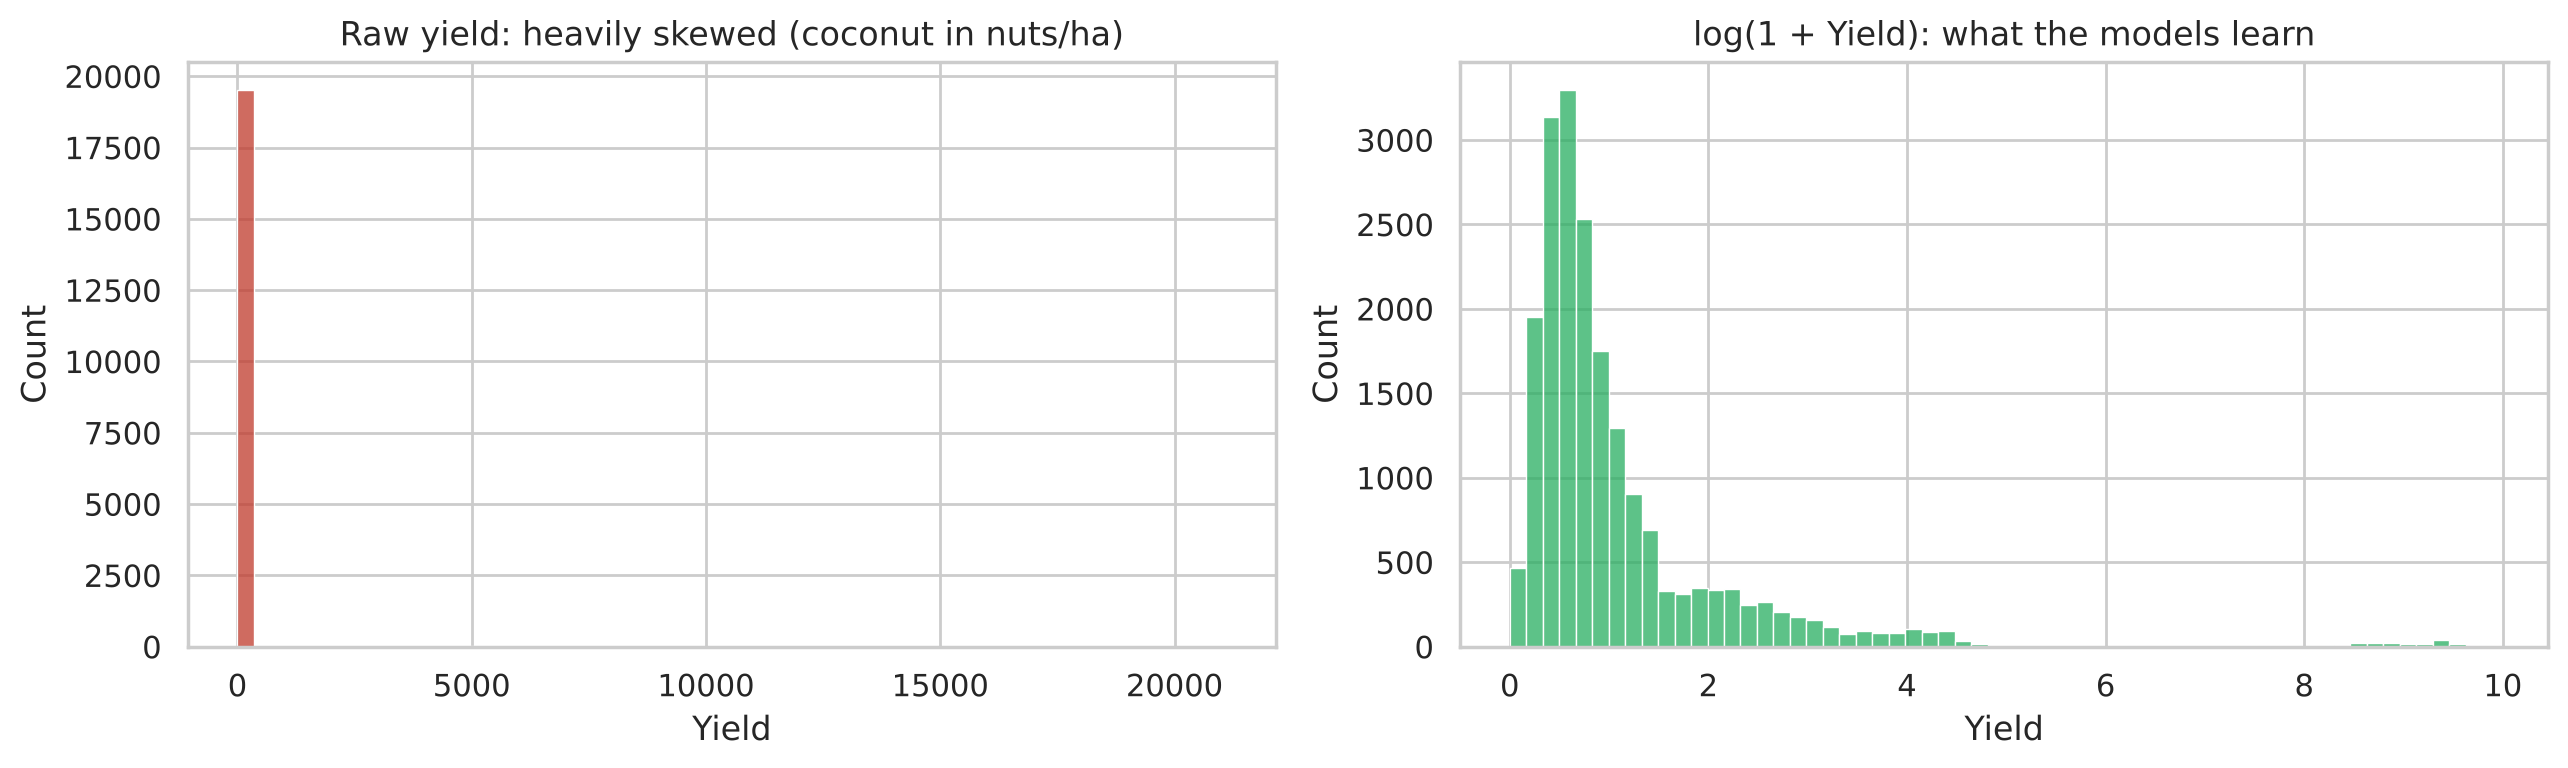

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Yield"], bins=60, ax=ax[0], color="#c0392b")
ax[0].set_title("Raw yield: heavily skewed (coconut in nuts/ha)")
sns.histplot(np.log1p(df["Yield"]), bins=60, ax=ax[1], color="#27ae60")
ax[1].set_title("log(1 + Yield): what the models learn")
plt.tight_layout(); plt.show()

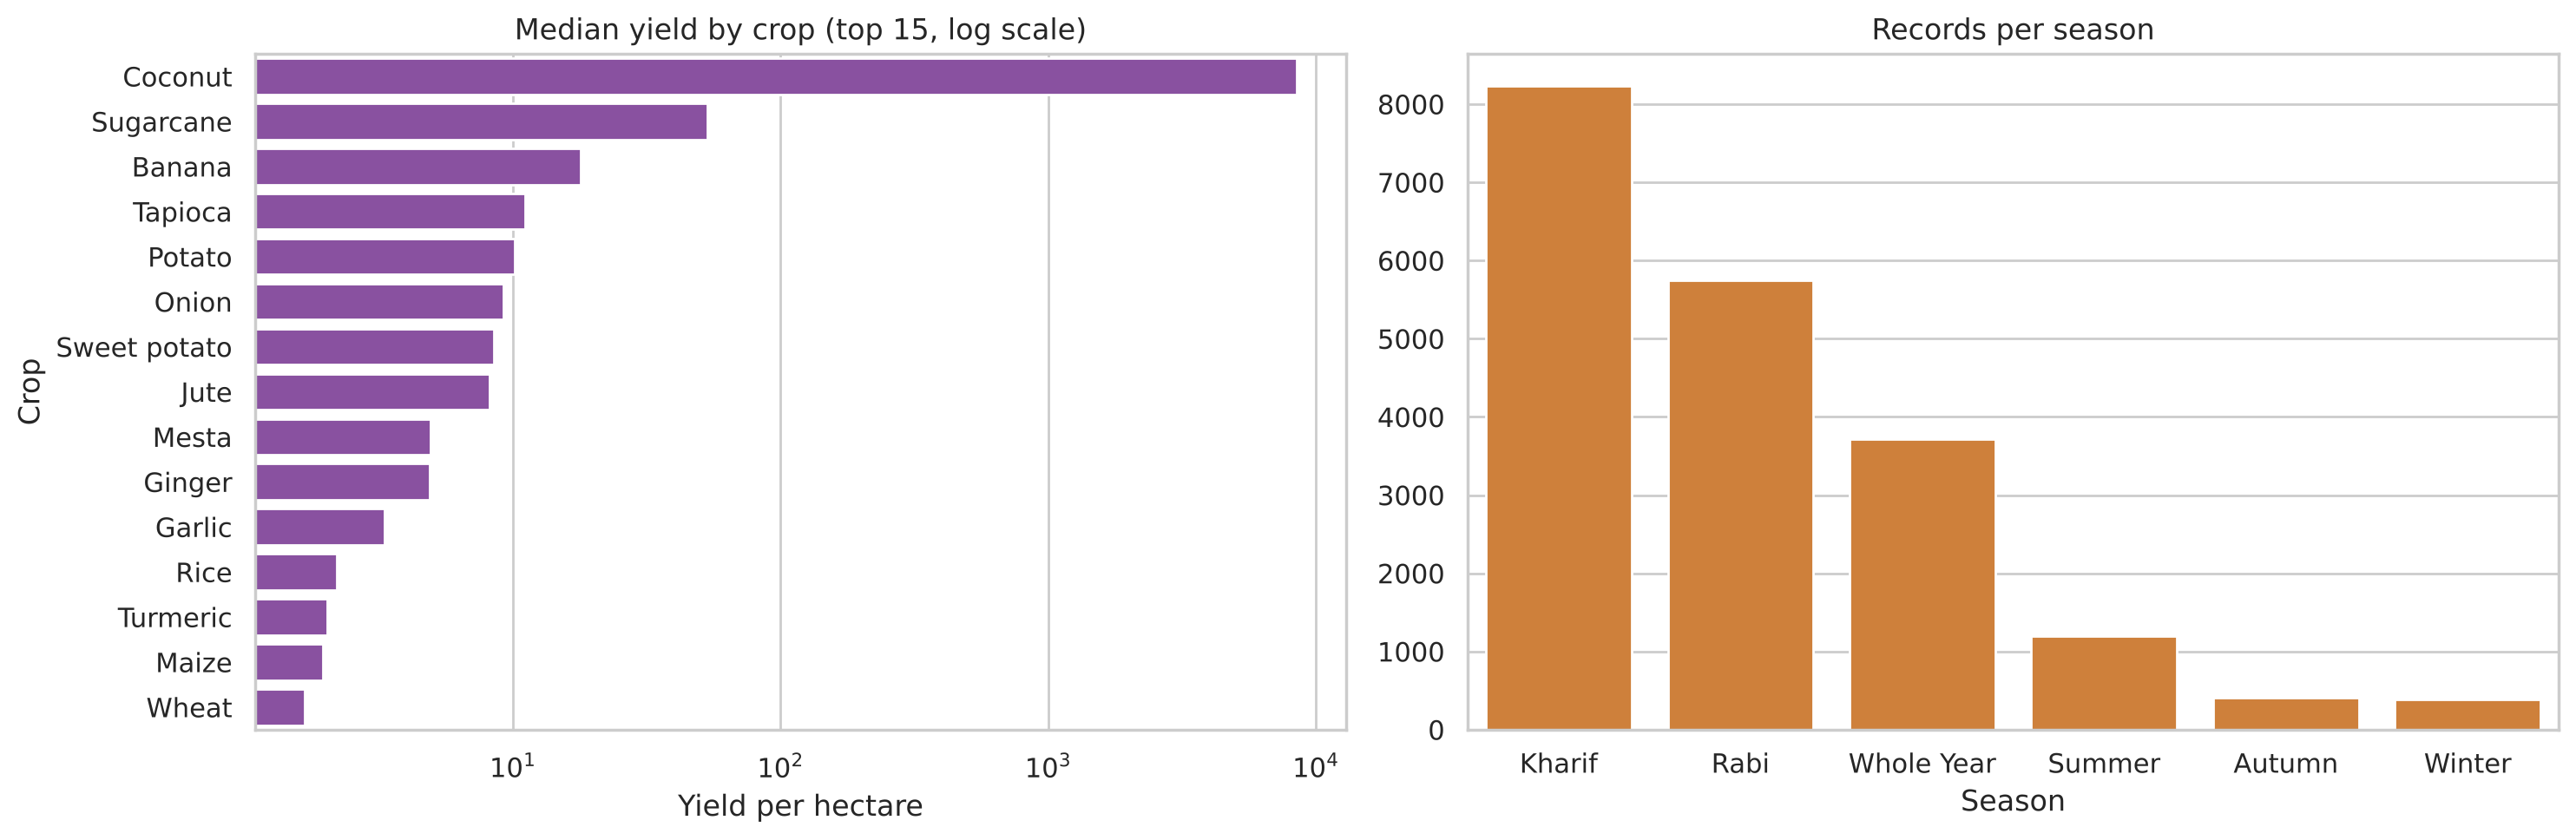

In [9]:
med = df.groupby("Crop")["Yield"].median().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=med.values, y=med.index, color="#8e44ad", ax=ax[0])
ax[0].set_xscale("log"); ax[0].set_title("Median yield by crop (top 15, log scale)"); ax[0].set_xlabel("Yield per hectare")
season_counts = df["Season"].value_counts()
sns.barplot(x=season_counts.index, y=season_counts.values, color="#e67e22", ax=ax[1])
ax[1].set_title("Records per season")
plt.tight_layout(); plt.show()

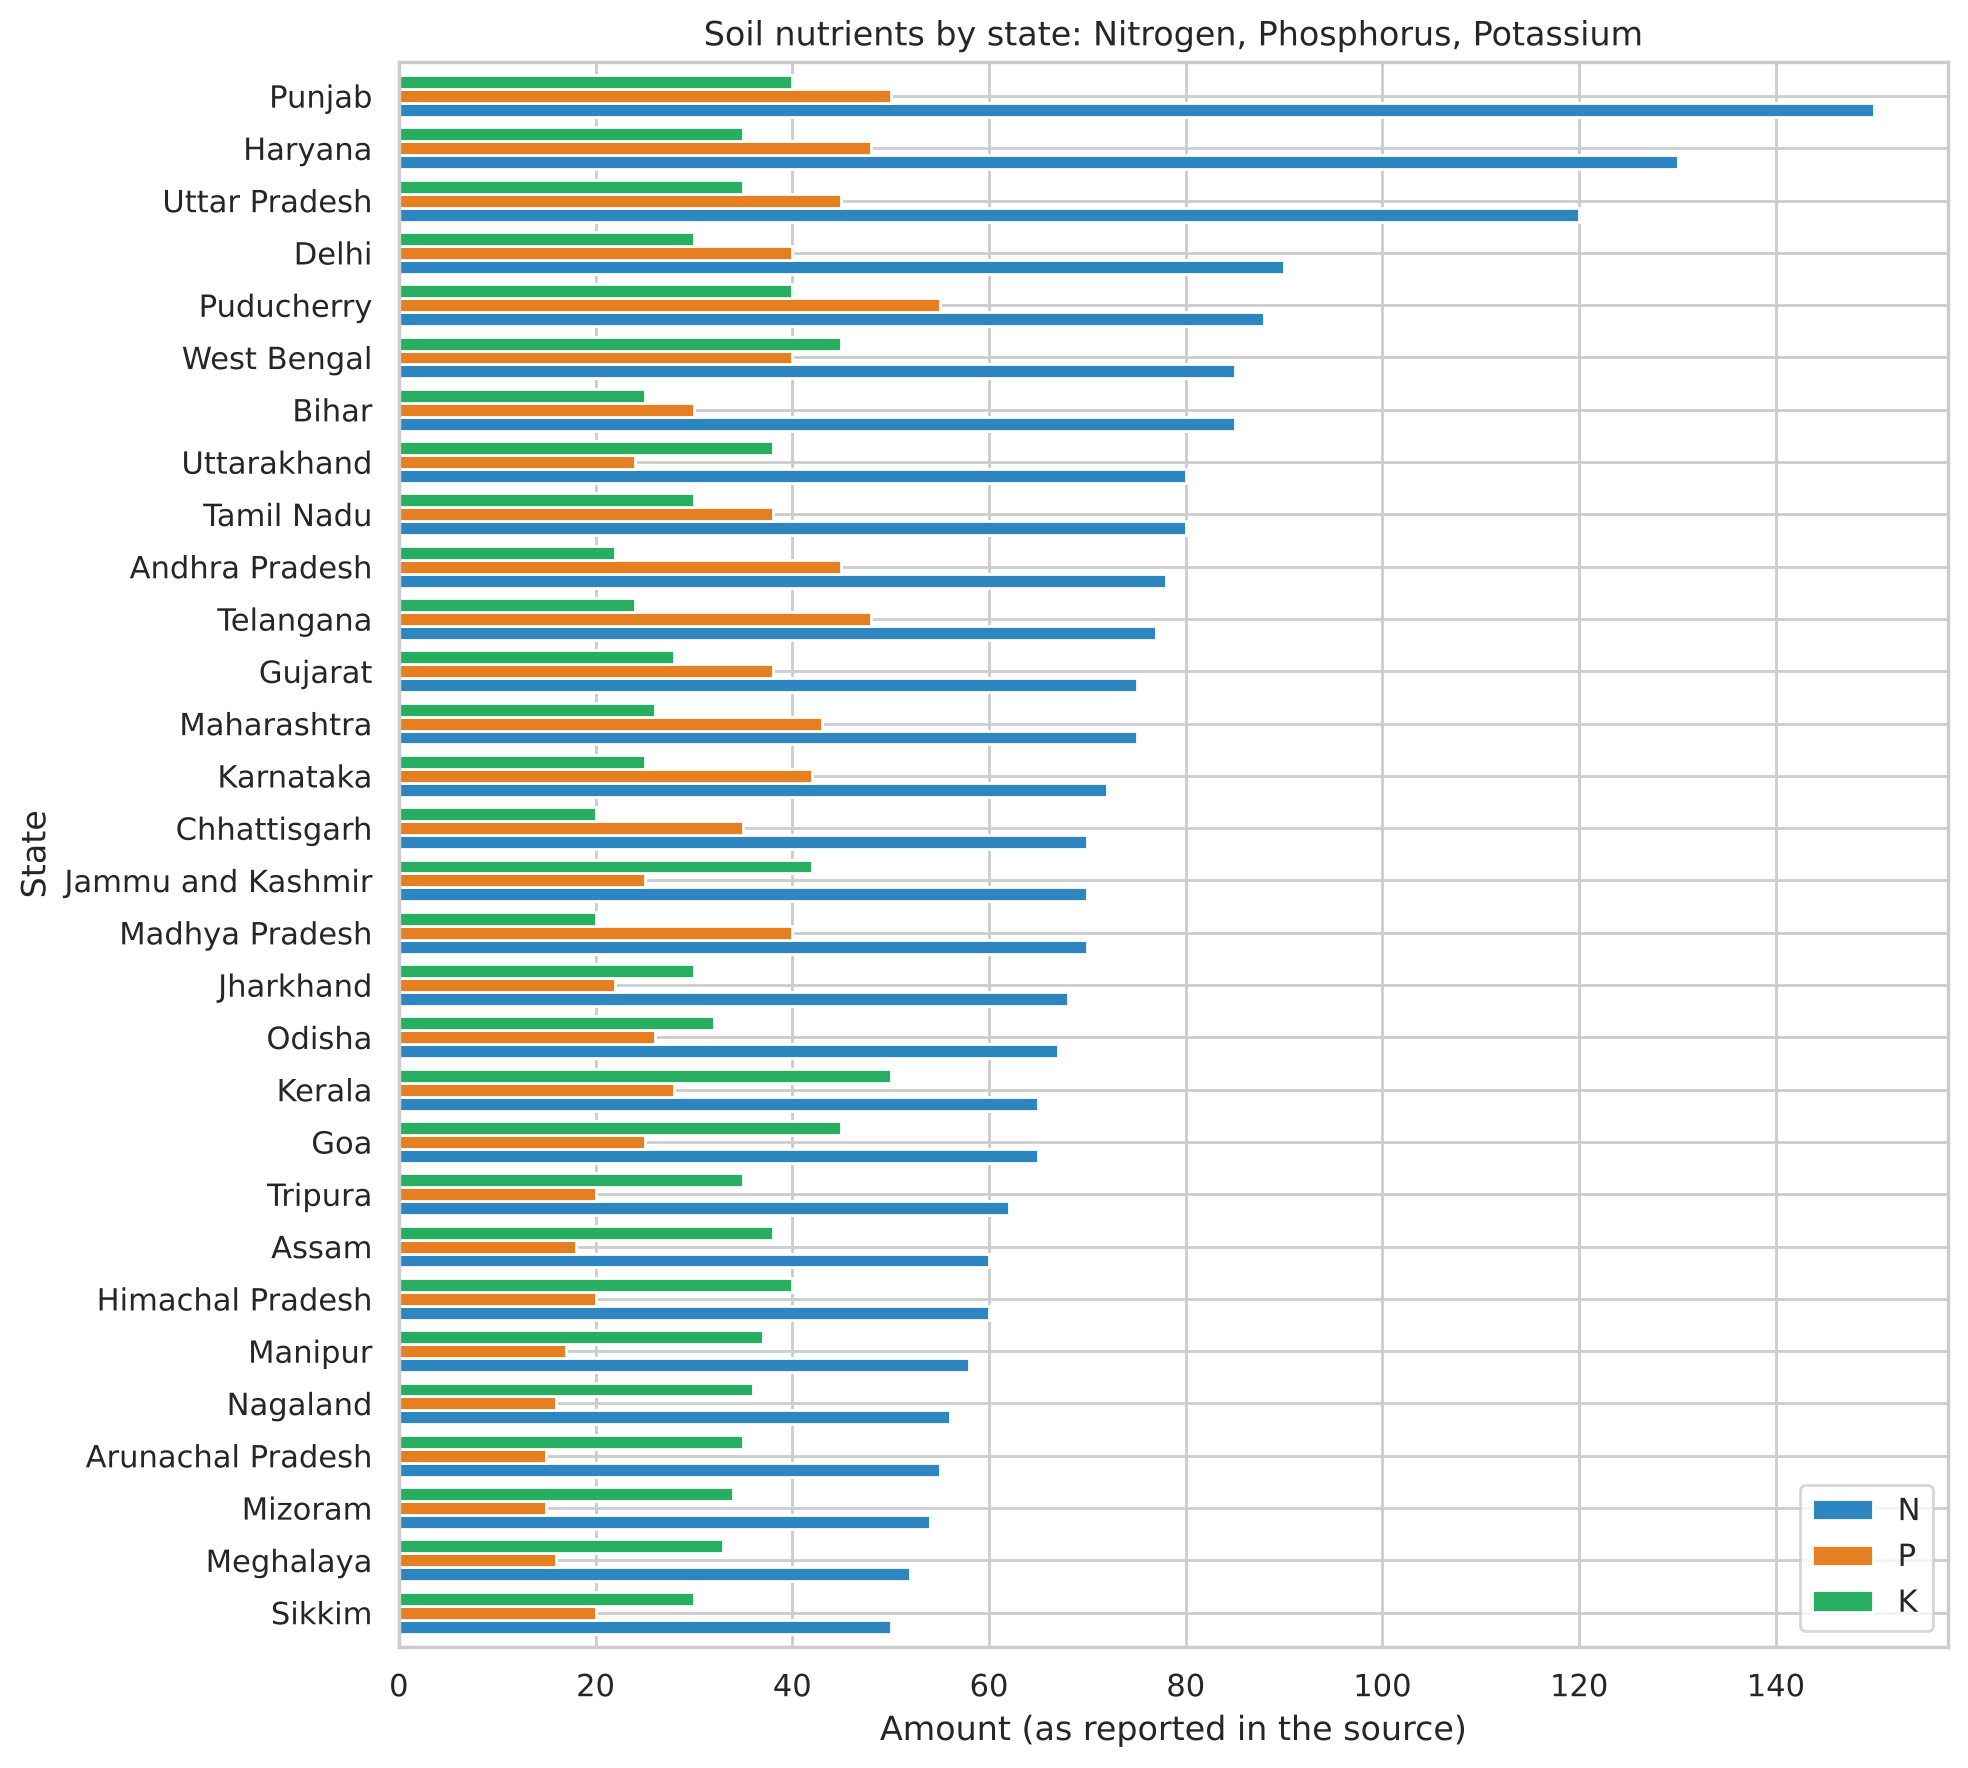

In [10]:
# Soil nutrient profile of each state
soil_plot = soil.set_index("State")[["N", "P", "K"]].sort_values("N")
ax = soil_plot.plot.barh(figsize=(10, 9), color=["#2e86c1", "#e67e22", "#27ae60"], width=0.8)
ax.set_title("Soil nutrients by state: Nitrogen, Phosphorus, Potassium"); ax.set_xlabel("Amount (as reported in the source)")
plt.tight_layout(); plt.show()

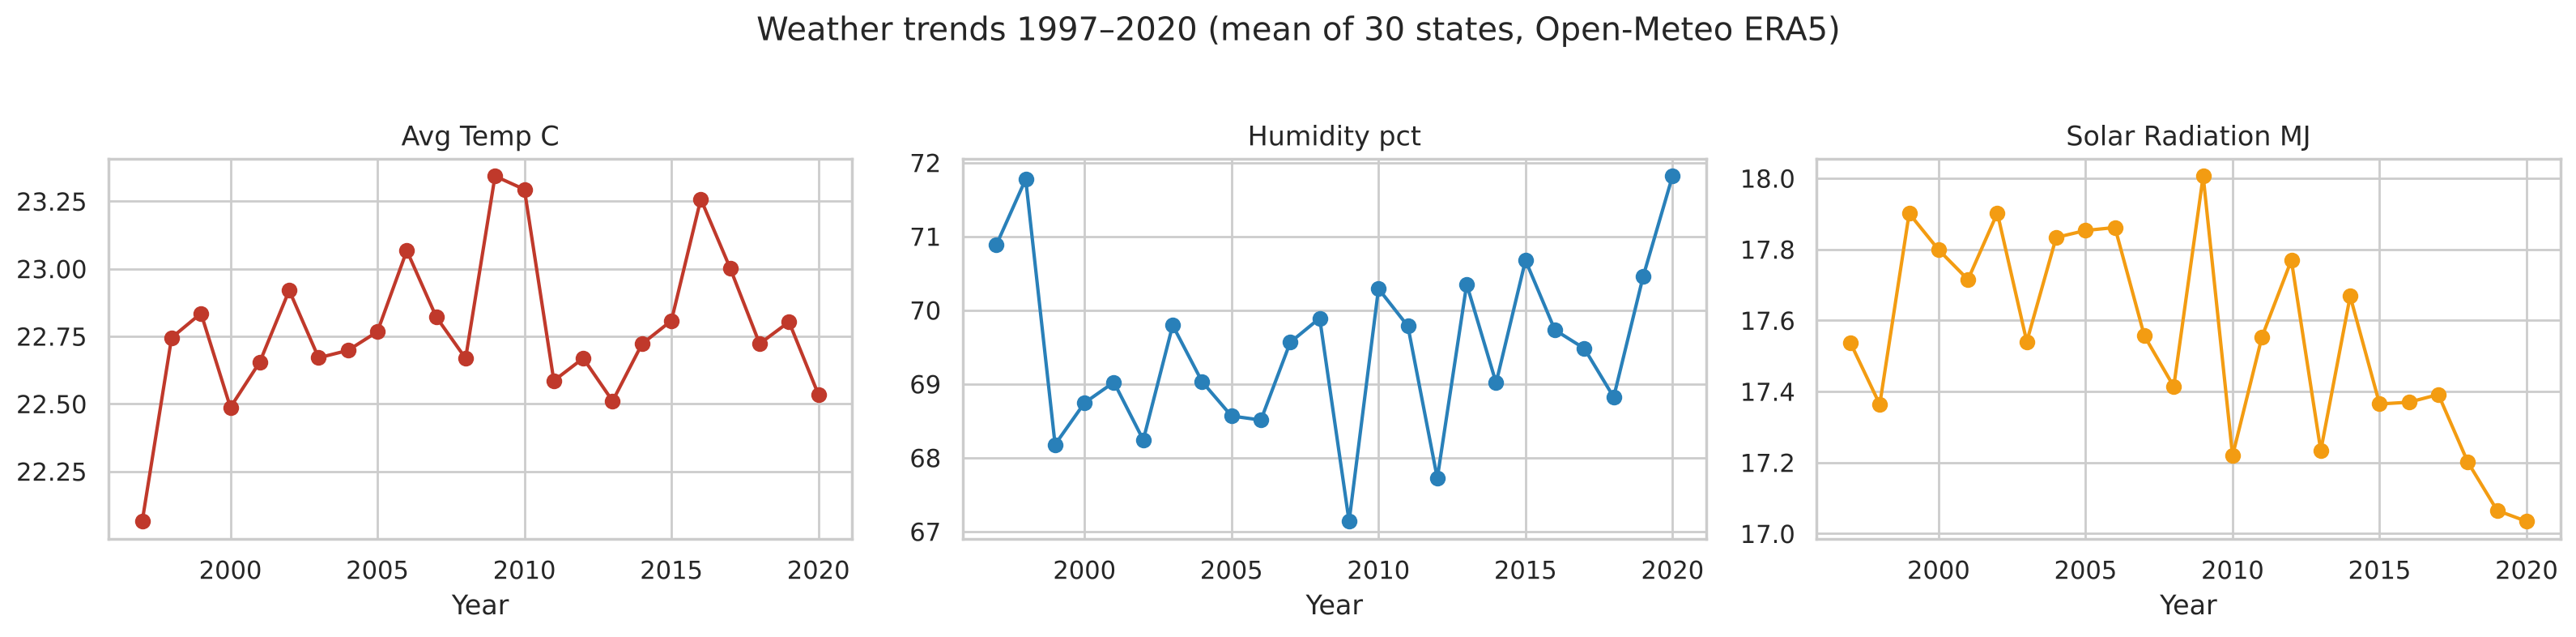

In [11]:
# Weather over the years (average across states)
yearly = weather.groupby("Crop_Year")[["Avg_Temp_C", "Humidity_pct", "Solar_Radiation_MJ"]].mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, c in zip(ax, yearly.columns, ["#c0392b", "#2980b9", "#f39c12"]):
    a.plot(yearly.index, yearly[col], marker="o", color=c); a.set_title(col.replace("_", " ")); a.set_xlabel("Year")
plt.suptitle("Weather trends 1997–2020 (mean of 30 states, Open-Meteo ERA5)", y=1.03)
plt.tight_layout(); plt.show()

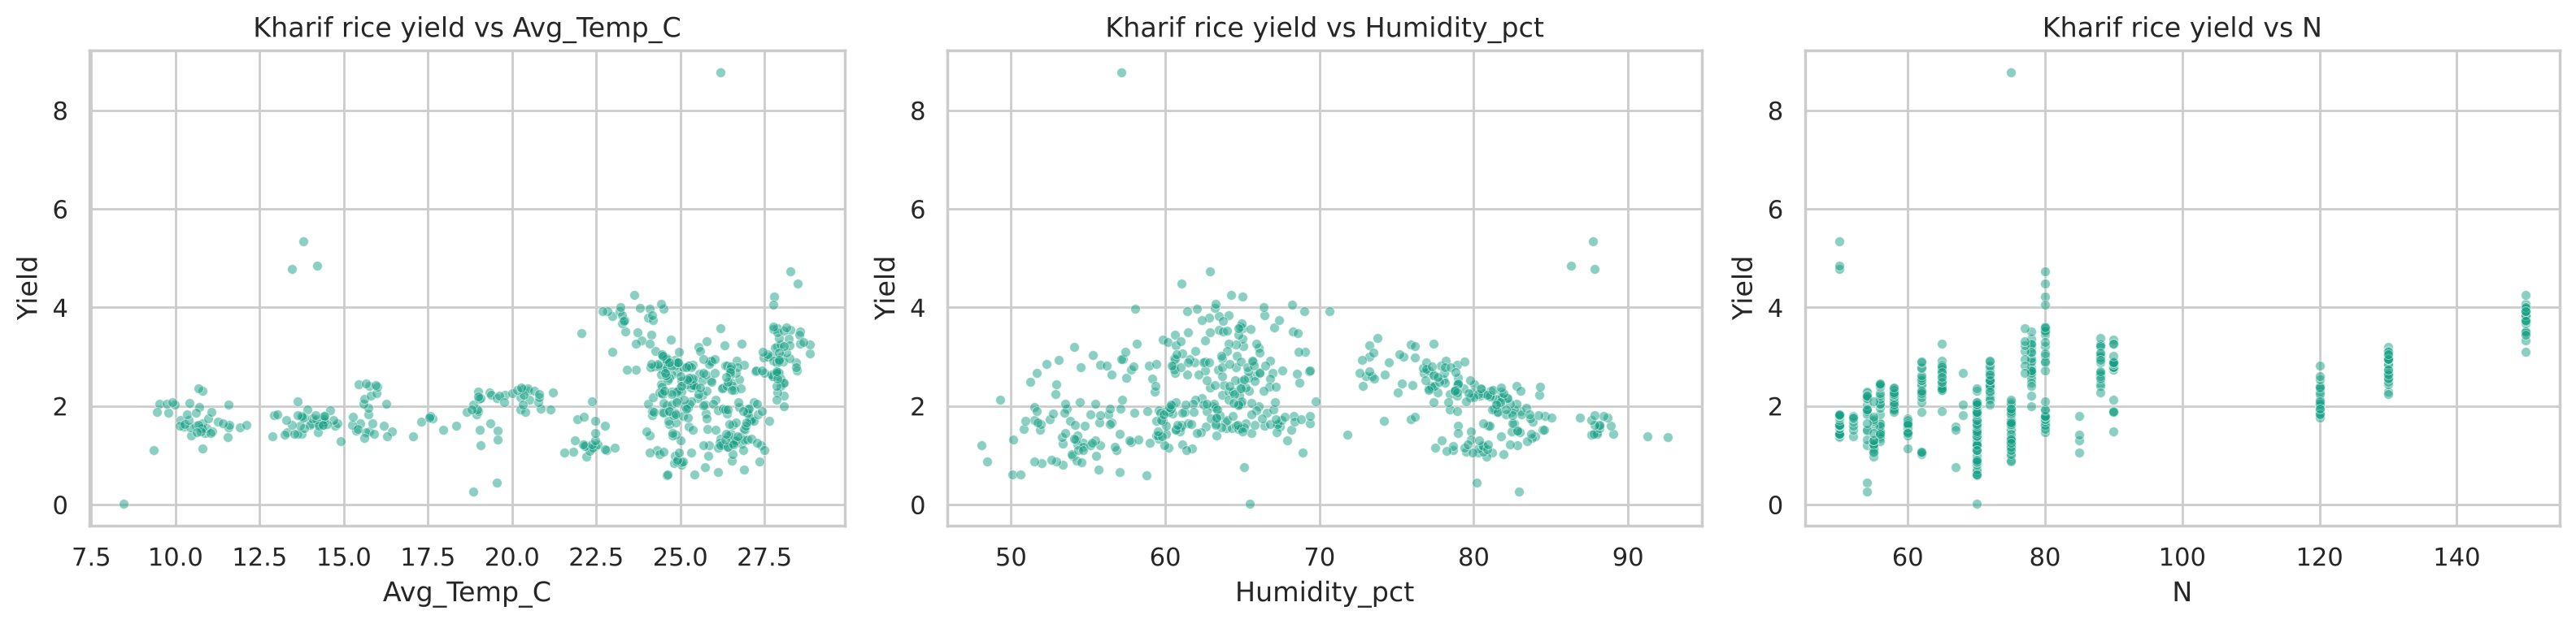

In [12]:
# Rice yield vs climate and soil: one point per state-year
rice = df[(df["Crop"] == "Rice") & (df["Season"] == "Kharif")]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["Avg_Temp_C", "Humidity_pct", "N"]):
    sns.scatterplot(data=rice, x=col, y="Yield", ax=a, alpha=0.5, s=18, color="#16a085")
    a.set_title(f"Kharif rice yield vs {col}")
plt.tight_layout(); plt.show()

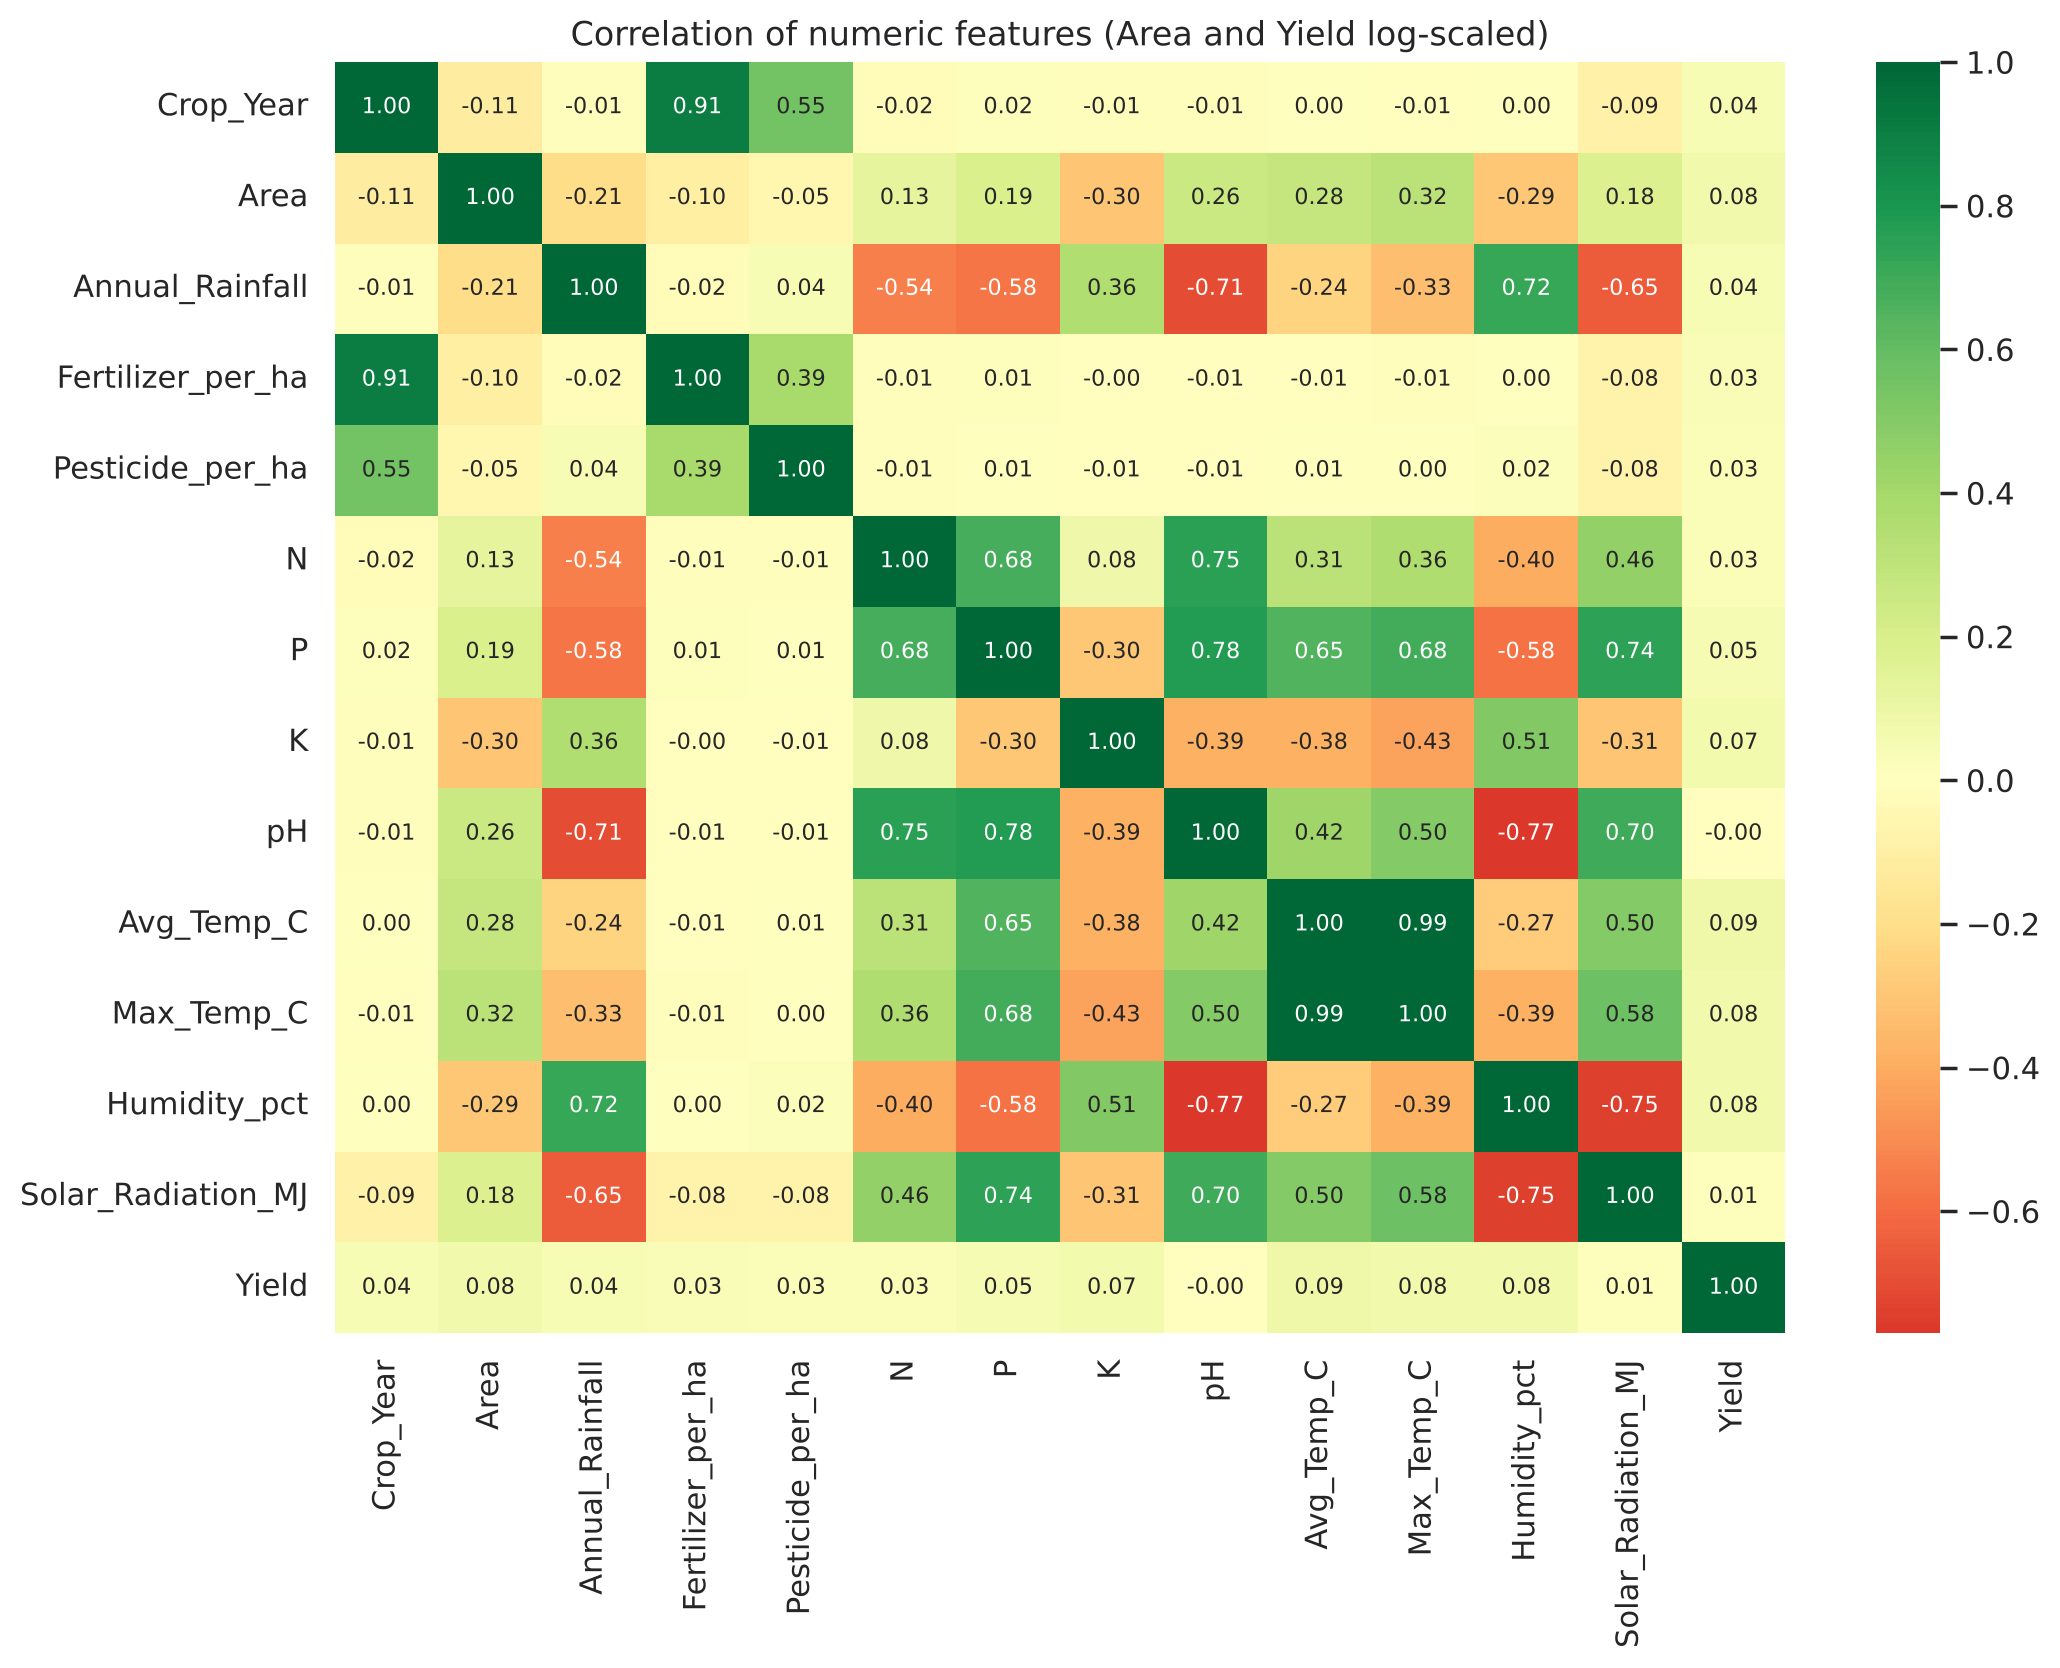

In [13]:
num_cols = ["Crop_Year", "Area", "Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha",
            "N", "P", "K", "pH", "Avg_Temp_C", "Max_Temp_C", "Humidity_pct", "Solar_Radiation_MJ", "Yield"]
corr_df = df[num_cols].copy()
corr_df[["Area", "Yield"]] = np.log1p(corr_df[["Area", "Yield"]])
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, annot_kws={"size": 8})
plt.title("Correlation of numeric features (Area and Yield log-scaled)")
plt.tight_layout(); plt.show()

**Observations**
* Yield depends mostly on **which crop** it is: sugarcane, banana and coconut are far above cereals and pulses.
* No single numeric feature has a strong straight-line correlation with yield across all crops; their effects depend on the crop,
  which is why non-linear models such as Random Forest are needed.
* Soil and weather differ strongly between states (e.g. Punjab and Haryana have the highest nitrogen; the north-east is the most humid).

## 5. Features, target and split
**Design choice:** instead of giving the model only the *name* of the state, each location is described by **what it is like**:
its soil (N, P, K, pH) and its weather that year. Section 8 shows this is as accurate as using the state name, and it means
the app responds when you change nitrogen, temperature, etc.

In [14]:
CAT_COLS  = ["Crop", "Season"]
LOG_COLS  = ["Area"]                                              # very large, skewed -> log then scale
NUM_COLS  = ["Crop_Year", "Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha",
             "N", "P", "K", "pH", "Avg_Temp_C", "Max_Temp_C", "Humidity_pct", "Solar_Radiation_MJ"]
FEATURES  = CAT_COLS + LOG_COLS + NUM_COLS

X = df[FEATURES]
y = np.log1p(df["Yield"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"{len(FEATURES)} input features | Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

15 input features | Train: 15751 rows | Test: 3938 rows


## 6. Preprocessing pipeline
One `ColumnTransformer` is shared by every model so the comparison is fair:
* **Crop, Season** → One-Hot Encoding
* **Area** → log1p, then Standard Scaling
* **all other numeric features** → Standard Scaling

In [15]:
def make_preprocessor(cat_cols, log_cols, num_cols):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), log_cols),
        ("num", StandardScaler(), num_cols),
    ])

preprocessor = make_preprocessor(CAT_COLS, LOG_COLS, NUM_COLS)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## 7. Train and compare 5 models
Each model sits in the same pipeline (`preprocessor → model`) and is scored with:
* **5-fold cross-validation R²** on the training set (used to rank the models)
* **Test R², MAE and RMSE** on the 20% hold-out set (log scale, comparable across crops)
* **Test R² in original units** after converting predictions back with `expm1`

In [16]:
models = {
    "Linear Regression (Ridge)": Ridge(alpha=1.0),
    "K-Nearest Neighbours":      KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "Decision Tree":             DecisionTreeRegressor(min_samples_leaf=3, random_state=RANDOM_STATE),
    "Random Forest":             RandomForestRegressor(n_estimators=150, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting":         HistGradientBoostingRegressor(max_iter=600, learning_rate=0.08, max_leaf_nodes=63,
                                                               random_state=RANDOM_STATE),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted = [], {}

for name, model in models.items():
    start = time.time()
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2", n_jobs=1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        "Model": name, "CV R² (mean)": cv_scores.mean(), "CV R² (std)": cv_scores.std(),
        "Test R²": r2_score(y_test, pred), "Test MAE": mean_absolute_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R² (original units)": r2_score(np.expm1(y_test), np.expm1(pred)),
        "Time (s)": time.time() - start,
    })
    print(f"{name:28s} {time.time() - start:6.1f}s | CV R² = {cv_scores.mean():.4f}")

results_df = pd.DataFrame(results).sort_values("CV R² (mean)", ascending=False).reset_index(drop=True)
results_df.index += 1
results_df.to_csv("outputs/model_comparison.csv", index_label="Rank")
results_df.round(4)

Linear Regression (Ridge)       0.2s | CV R² = 0.8482


K-Nearest Neighbours            1.0s | CV R² = 0.8149


Decision Tree                   1.7s | CV R² = 0.9377


Random Forest                  42.1s | CV R² = 0.9589


Gradient Boosting              14.0s | CV R² = 0.9440


,Model,CV R² (mean),CV R² (std),Test R²,Test MAE,Test RMSE,Test R² (original units),Time (s)
1,Random Forest,0.9589,0.0053,0.9728,0.1032,0.1851,0.9666,42.1443
2,Gradient Boosting,0.9440,0.0073,0.9628,0.1272,0.2166,0.8443,14.0064
3,Decision Tree,0.9377,0.0048,0.9500,0.1302,0.2511,0.9644,1.6721
4,Linear Regression (Ridge),0.8482,0.0194,0.8545,0.2620,0.4282,0.7327,0.2468
5,K-Nearest Neighbours,0.8149,0.0113,0.8400,0.2328,0.4490,0.5807,0.9839


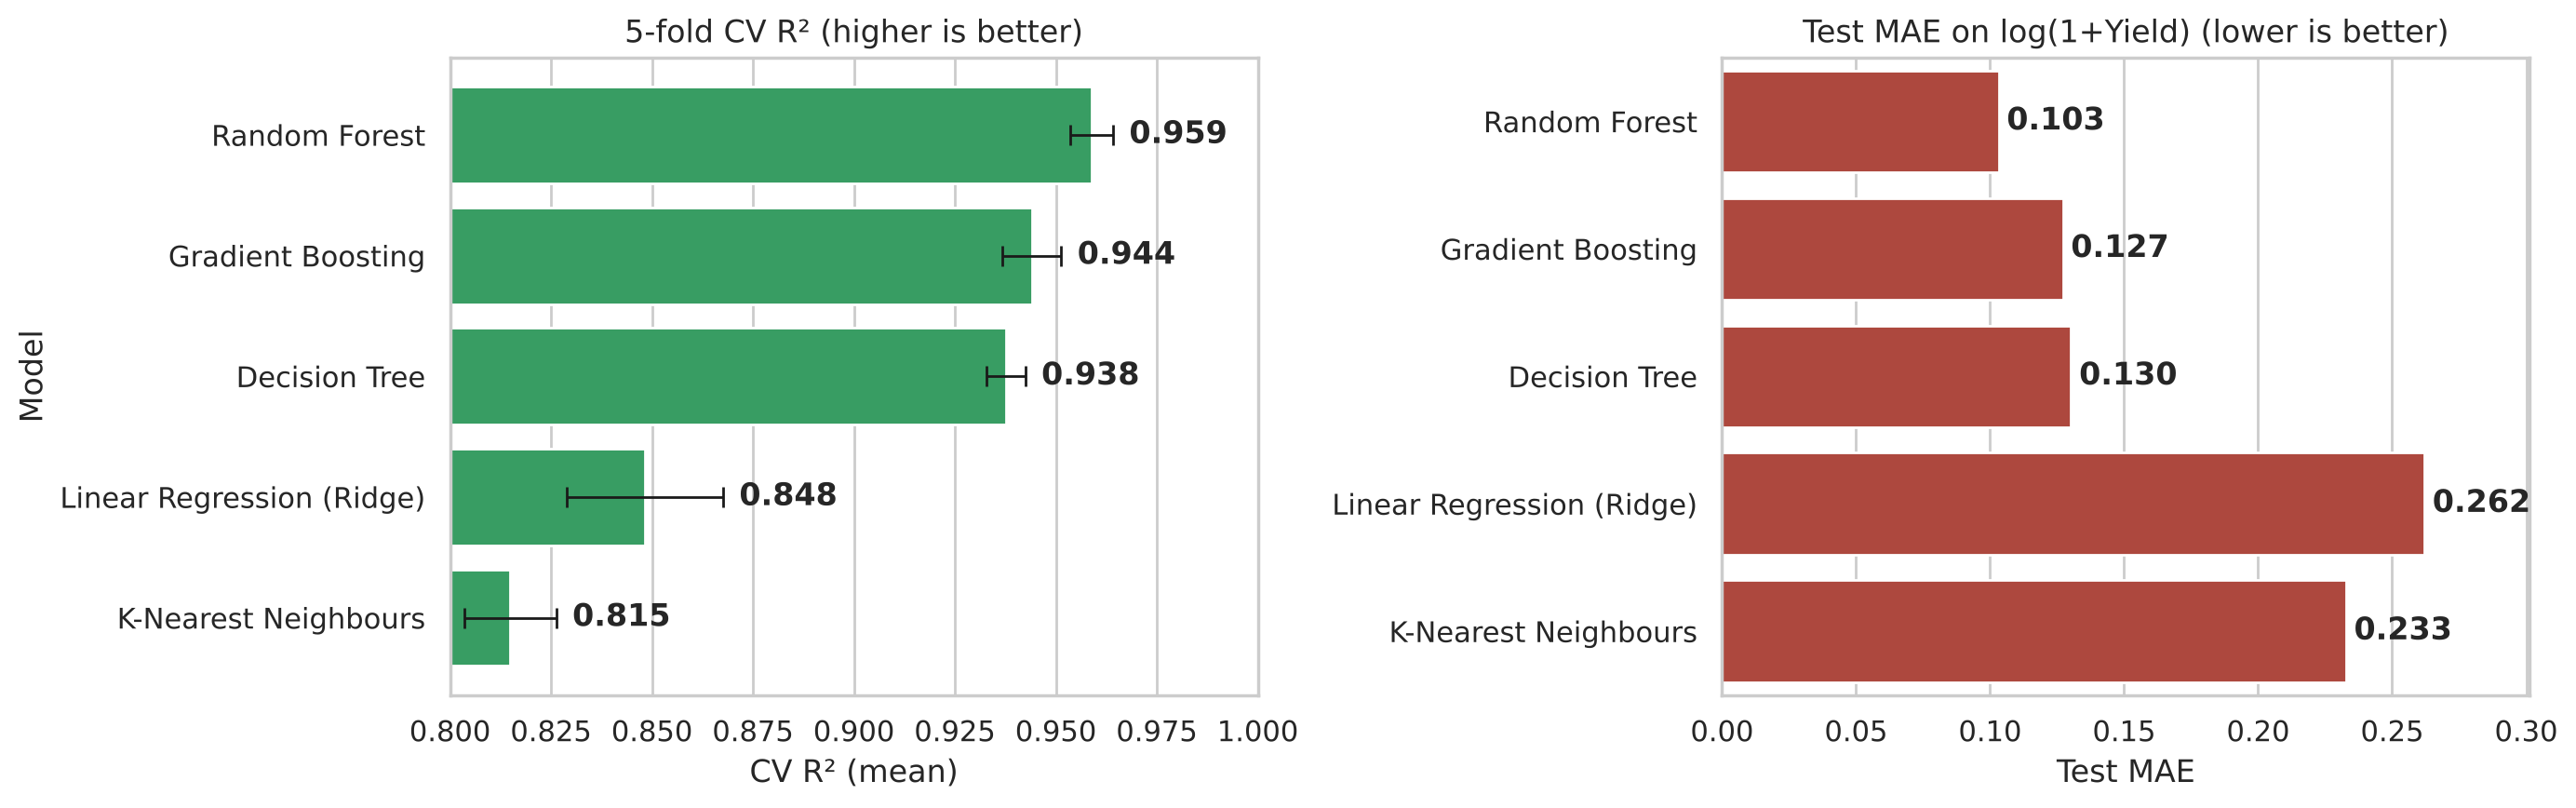

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
order = results_df["Model"]
sns.barplot(data=results_df, x="CV R² (mean)", y="Model", order=order, ax=ax[0], color="#27ae60")
ax[0].errorbar(results_df["CV R² (mean)"], range(len(results_df)), xerr=results_df["CV R² (std)"],
               fmt="none", c="k", capsize=4, lw=1)
ax[0].set_xlim(0.8, 1.0); ax[0].set_title("5-fold CV R² (higher is better)")
for i, (v, sd) in enumerate(zip(results_df["CV R² (mean)"], results_df["CV R² (std)"])):
    ax[0].text(v + sd + 0.004, i, f"{v:.3f}", va="center", fontweight="bold")
sns.barplot(data=results_df, x="Test MAE", y="Model", order=order, ax=ax[1], color="#c0392b")
ax[1].set_title("Test MAE on log(1+Yield) (lower is better)")
for i, v in enumerate(results_df["Test MAE"]):
    ax[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontweight="bold")
ax[1].set_xlim(0, results_df["Test MAE"].max() * 1.15); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig("outputs/model_comparison.png", dpi=150); plt.show()

**Reading the table:** models are scored mainly on the log scale because yields range from under 1 t/ha to thousands of coconuts/ha.
On the original scale a few coconut records dominate the error, which is why a model's *original-units* R² can look low even when
its log-scale scores are good. The best model is chosen by cross-validation R².

## 8. Which data helps? (feature-group study)
The best model is retrained with different groups of inputs to measure what each data source contributes
(5-fold CV R² on the training set).

Crop + season + farm inputs only           CV R² = 0.9248


+ State name                               CV R² = 0.9583


+ Soil (N, P, K, pH)                       CV R² = 0.9615


+ Weather                                  CV R² = 0.9482


+ Soil + Weather  (final model)            CV R² = 0.9589


+ Soil + Weather + State name              CV R² = 0.9593


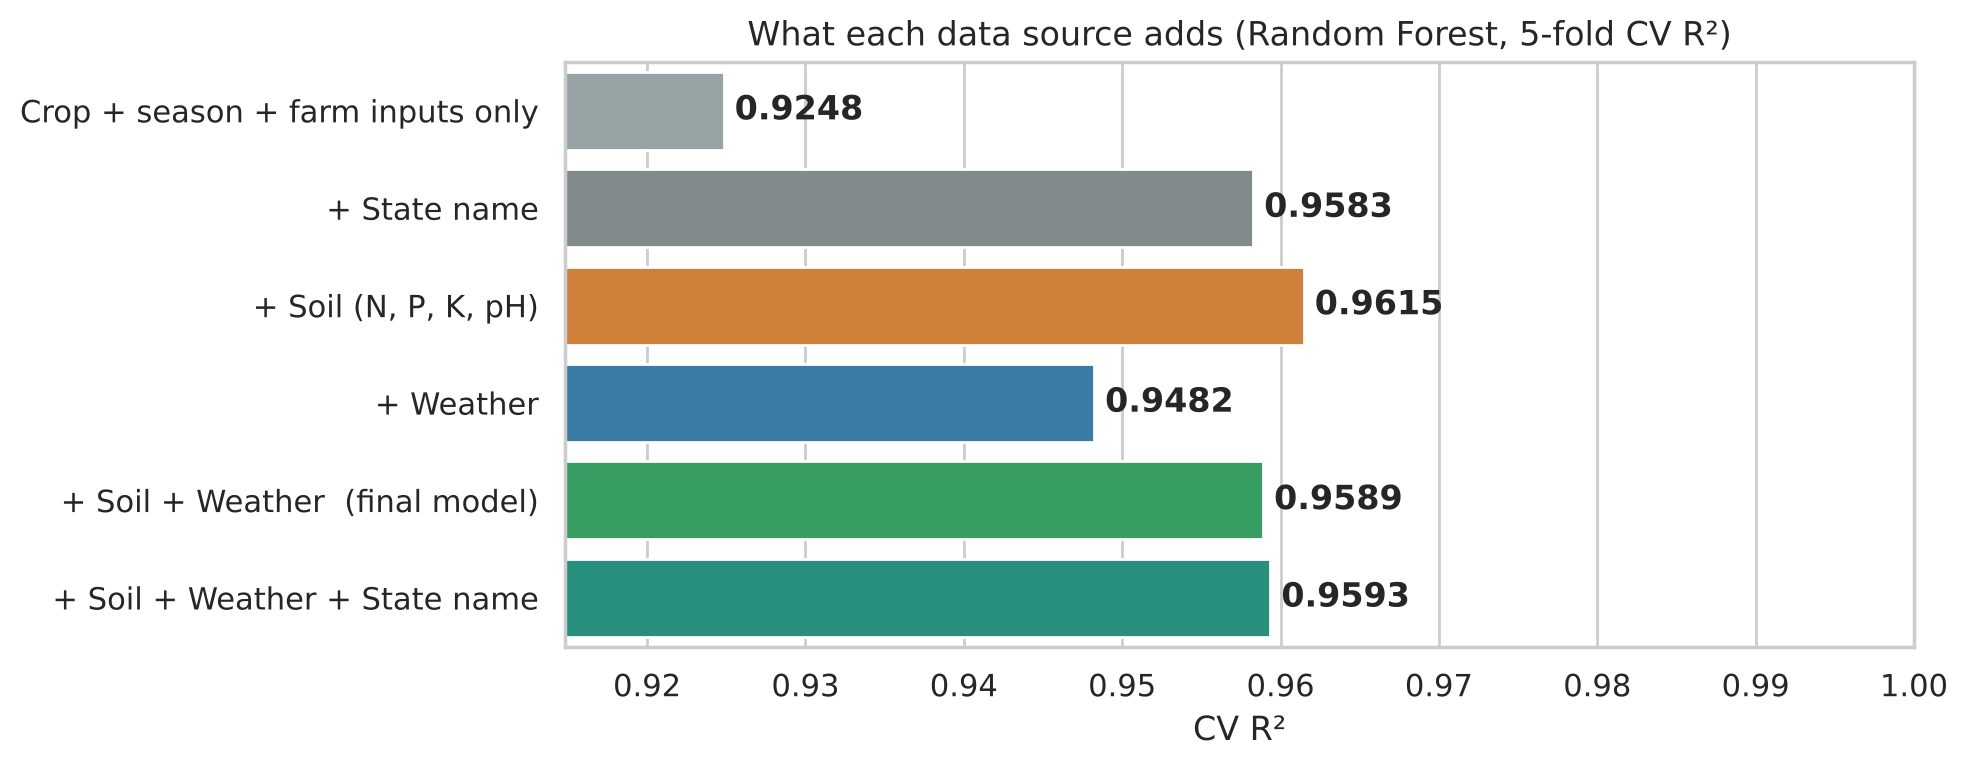

In [18]:
best_name = results_df.iloc[0]["Model"]
base_model = models[best_name]
BASE_NUM = ["Crop_Year", "Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha"]
SOIL = ["N", "P", "K", "pH"]
WEATHER = ["Avg_Temp_C", "Max_Temp_C", "Humidity_pct", "Solar_Radiation_MJ"]
X_train_full = df.loc[X_train.index]

feature_sets = {
    "Crop + season + farm inputs only":         (["Crop", "Season"], BASE_NUM),
    "+ State name":                             (["Crop", "Season", "State"], BASE_NUM),
    "+ Soil (N, P, K, pH)":                     (["Crop", "Season"], BASE_NUM + SOIL),
    "+ Weather":                                (["Crop", "Season"], BASE_NUM + WEATHER),
    "+ Soil + Weather  (final model)":          (["Crop", "Season"], BASE_NUM + SOIL + WEATHER),
    "+ Soil + Weather + State name":            (["Crop", "Season", "State"], BASE_NUM + SOIL + WEATHER),
}
ablation = []
for label, (cats, nums) in feature_sets.items():
    pipe = Pipeline([("preprocess", make_preprocessor(cats, ["Area"], nums)), ("model", clone(base_model))])
    score = cross_val_score(pipe, X_train_full[cats + ["Area"] + nums], y_train, cv=cv, scoring="r2").mean()
    ablation.append({"Feature set": label, "CV R²": score})
    print(f"{label:42s} CV R² = {score:.4f}")
ablation_df = pd.DataFrame(ablation)
ablation_df.to_csv("outputs/feature_group_study.csv", index=False)

plt.figure(figsize=(10, 4))
colors = ["#95a5a6", "#7f8c8d", "#e67e22", "#2980b9", "#27ae60", "#16a085"]
ax = sns.barplot(data=ablation_df, x="CV R²", y="Feature set", palette=colors)
lo = ablation_df["CV R²"].min()
ax.set_xlim(lo - 0.01, 1.0)
for i, v in enumerate(ablation_df["CV R²"]):
    ax.text(v + 0.0007, i, f"{v:.4f}", va="center", fontweight="bold")
plt.title(f"What each data source adds ({best_name}, 5-fold CV R²)"); plt.ylabel("")
plt.tight_layout(); plt.savefig("outputs/feature_group_study.png", dpi=150); plt.show()

In [19]:
a = ablation_df.set_index("Feature set")["CV R²"]
print(f"Adding location information raises CV R² from {a.iloc[0]:.4f} to about {a.iloc[1:].max():.4f}.")
print(f"State name only: {a['+ State name']:.4f}  |  Soil + weather instead of the name: {a['+ Soil + Weather  (final model)']:.4f}"
      f"  (difference {a['+ Soil + Weather  (final model)'] - a['+ State name']:+.4f})")

Adding location information raises CV R² from 0.9248 to about 0.9615.
State name only: 0.9583  |  Soil + weather instead of the name: 0.9589  (difference +0.0006)


**Takeaway**
* Location information adds a lot of accuracy (first bar vs the rest).
* Describing each state by **what it is like** (soil + weather) scores about the same as giving the model the state's name.
* Soil on its own scores slightly higher than soil + weather. The weather here is one yearly average per state, which hides what
  happens inside a growing season, so it adds little on top of soil. The difference is within the variation between CV folds.
* The final model keeps **soil + weather**: it is as accurate as using the state's name, its predictions can be explained in terms
  of nutrients and climate, and the app reacts when you change N, P, K, temperature or humidity.

## 9. Tune the best model
`RandomizedSearchCV` tries different Random Forest settings with 3-fold cross-validation.

In [20]:
search_space = {
    "model__n_estimators": [150, 200],
    "model__max_features": [0.3, 0.5, 0.7],
    "model__min_samples_leaf": [1, 2, 3],
    "model__max_depth": [None, 30],
}
rf_pipe = Pipeline([("preprocess", preprocessor),
                    ("model", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE))])
search = RandomizedSearchCV(rf_pipe, search_space, n_iter=8, cv=3, scoring="r2",
                            random_state=RANDOM_STATE, n_jobs=1, verbose=0)
start = time.time(); search.fit(X_train, y_train)
print(f"Search finished in {time.time() - start:.0f}s")
print("Best settings:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f"Best CV R²: {search.best_score_:.4f}")

tuning_table = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "rank_test_score"]]
                .sort_values("rank_test_score").rename(columns={"mean_test_score": "CV R²", "rank_test_score": "Rank"}))
tuning_table["params"] = tuning_table["params"].apply(lambda p: {k.replace("model__", ""): v for k, v in p.items()})
tuning_table.round(4)

Search finished in 182s
Best settings: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': None}
Best CV R²: 0.9551


,params,CV R²,Rank
1,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.9551,1
7,"{'n_estimators': 150, 'min_samples_leaf': 1, '...",0.9548,2
5,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.9506,3
3,"{'n_estimators': 150, 'min_samples_leaf': 1, '...",0.9503,4
2,"{'n_estimators': 150, 'min_samples_leaf': 2, '...",0.9455,5
4,"{'n_estimators': 150, 'min_samples_leaf': 3, '...",0.9453,6
6,"{'n_estimators': 200, 'min_samples_leaf': 2, '...",0.9423,7
0,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",0.9412,8


In [21]:
tuned = search.best_estimator_
default_test = r2_score(y_test, fitted["Random Forest"].predict(X_test))
tuned_test = r2_score(y_test, tuned.predict(X_test))
print(f"Random Forest test R²  default: {default_test:.4f}  |  tuned: {tuned_test:.4f}")
final_pipe = tuned if tuned_test >= default_test else fitted["Random Forest"]
final_name = "Random Forest (tuned)" if final_pipe is tuned else "Random Forest"
print("Using:", final_name)
rf_params = {k: v for k, v in final_pipe.named_steps["model"].get_params().items()
             if k in ("n_estimators", "max_features", "min_samples_leaf", "max_depth")}
json.dump({"model_name": final_name, "params": rf_params}, open("outputs/best_params.json", "w"), indent=2)
rf_params

Random Forest test R²  default: 0.9728  |  tuned: 0.9724
Using: Random Forest


{'max_depth': None,
 'max_features': 0.5,
 'min_samples_leaf': 1,
 'n_estimators': 150}

## 10. Evaluate the final model

Test R² (log): 0.9728 | MAE (log): 0.1032 | R² (original units): 0.9666


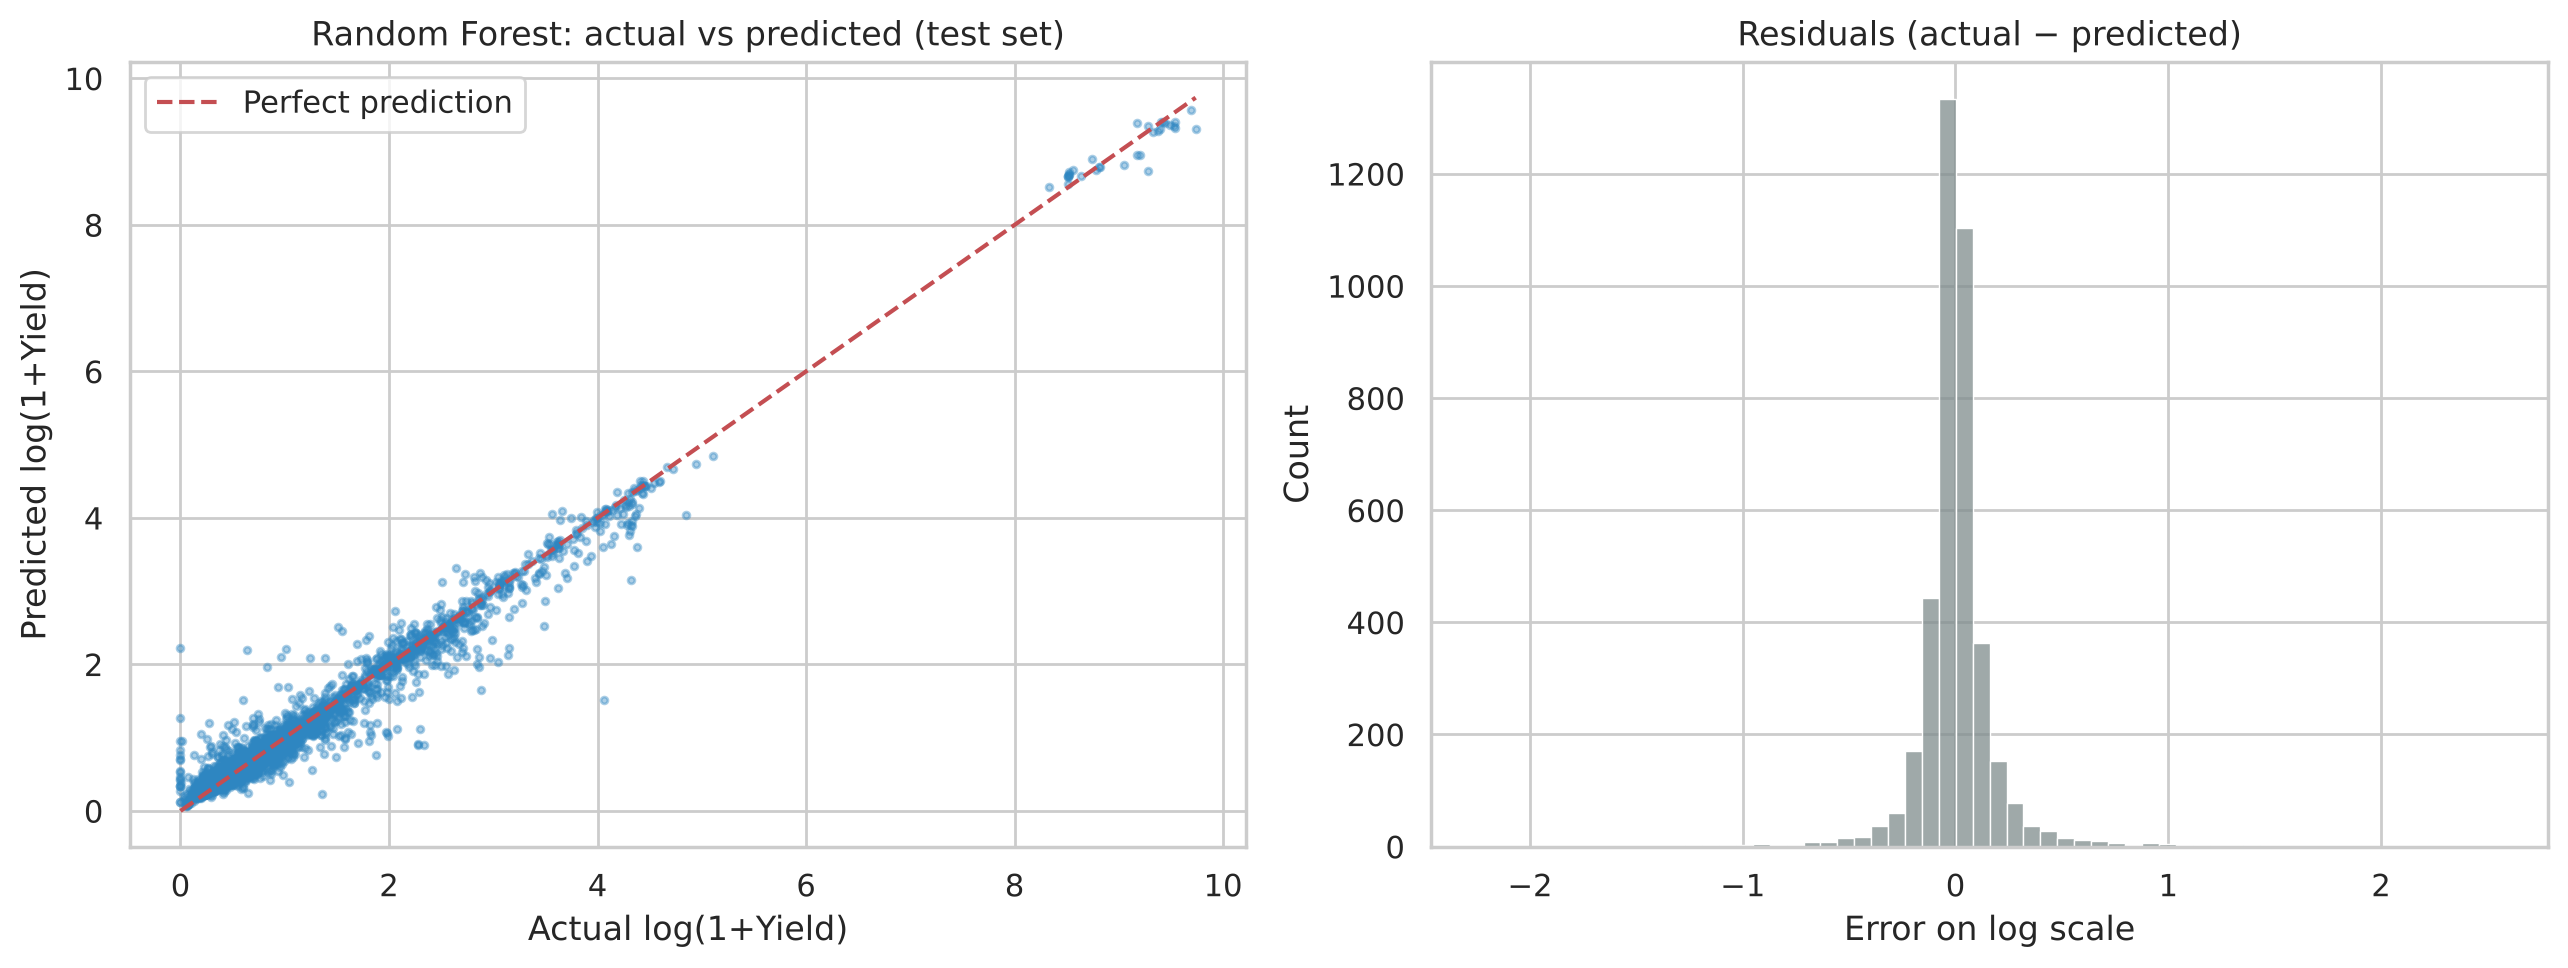

In [22]:
pred = final_pipe.predict(X_test)
print(f"Test R² (log): {r2_score(y_test, pred):.4f} | MAE (log): {mean_absolute_error(y_test, pred):.4f} | "
      f"R² (original units): {r2_score(np.expm1(y_test), np.expm1(pred)):.4f}")
summary = {"final_model": final_name, "final_test_r2": r2_score(y_test, pred),
           "final_test_mae": mean_absolute_error(y_test, pred),
           "final_test_r2_orig": r2_score(np.expm1(y_test), np.expm1(pred))}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, s=6, alpha=0.4, color="#2e86c1")
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", lw=1.5, label="Perfect prediction")
ax[0].set_xlabel("Actual log(1+Yield)"); ax[0].set_ylabel("Predicted log(1+Yield)")
ax[0].set_title(f"{final_name}: actual vs predicted (test set)"); ax[0].legend()
sns.histplot(y_test - pred, bins=60, ax=ax[1], color="#7f8c8d")
ax[1].set_title("Residuals (actual − predicted)"); ax[1].set_xlabel("Error on log scale")
plt.tight_layout(); plt.savefig("outputs/actual_vs_predicted.png", dpi=150); plt.show()

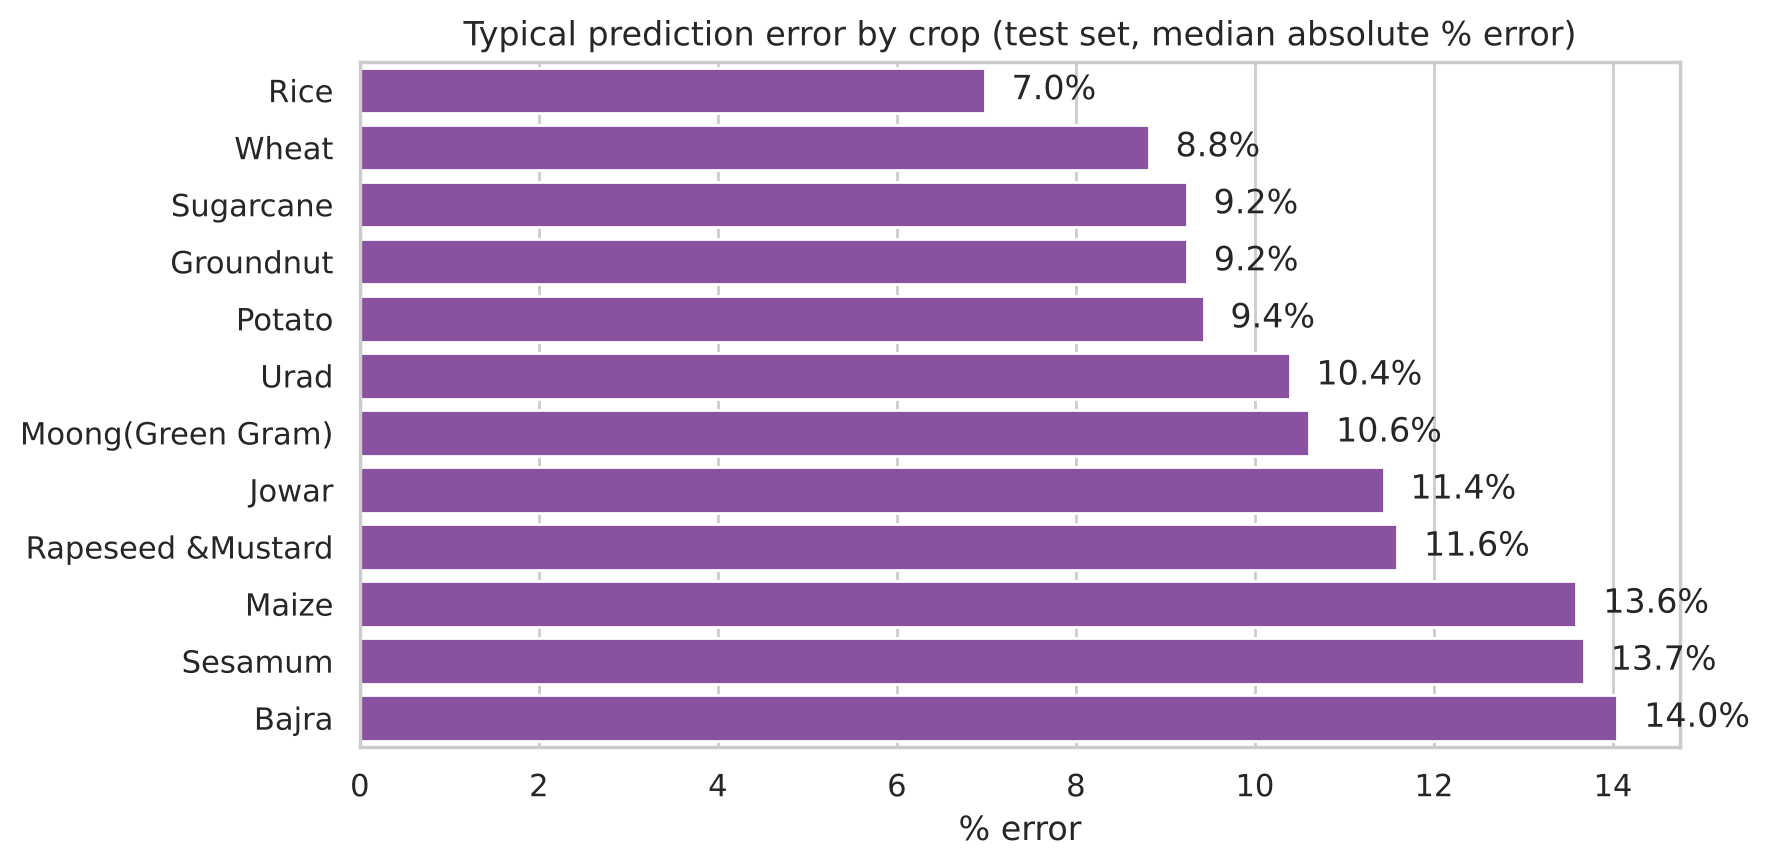

In [23]:
# Accuracy for the 12 most common crops: median percentage error on the test set
test_eval = df.loc[X_test.index, ["Crop"]].copy()
test_eval["Actual"] = np.expm1(y_test); test_eval["Predicted"] = np.expm1(pred)
test_eval = test_eval[test_eval["Actual"] > 0]
test_eval["Abs % error"] = (test_eval["Predicted"] - test_eval["Actual"]).abs() / test_eval["Actual"] * 100
top = df["Crop"].value_counts().head(12).index
by_crop = (test_eval[test_eval["Crop"].isin(top)].groupby("Crop")["Abs % error"].median()
           .sort_values().rename("Median % error"))
plt.figure(figsize=(9, 4.5))
sns.barplot(x=by_crop.values, y=by_crop.index, color="#8e44ad")
for i, v in enumerate(by_crop.values):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.title("Typical prediction error by crop (test set, median absolute % error)"); plt.xlabel("% error"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 11. Feature importance: what the Random Forest relies on
Two complementary methods:
* **Built-in (impurity) importance:** how much each input reduces error inside the trees. One-hot columns (e.g. every crop) are summed back into one feature.
* **Permutation importance:** how much test-set R² drops when a feature's values are shuffled. This is model-agnostic and measured on unseen data.

In [24]:
rf = final_pipe.named_steps["model"]
names = final_pipe.named_steps["preprocess"].get_feature_names_out()
def original_feature(n):
    block, col = n.split("__", 1)
    if block == "cat":                              # one-hot columns look like "cat__Crop_Rice"
        for c in CAT_COLS:
            if col.startswith(c + "_"):
                return c
    return col
impurity = (pd.Series(rf.feature_importances_, index=[original_feature(n) for n in names])
            .groupby(level=0).sum().sort_values(ascending=False))

perm = permutation_importance(final_pipe, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
permutation = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=FEATURES)
permutation = permutation.sort_values("mean", ascending=False)

importance_table = pd.DataFrame({"Built-in importance (share)": impurity,
                                 "Permutation importance (R² drop)": permutation["mean"]}).sort_values(
                                 "Built-in importance (share)", ascending=False)
importance_table.to_csv("outputs/feature_importance.csv", index_label="Feature")
importance_table.round(4)

,Built-in importance (share),Permutation importance (R² drop)
Crop,0.7737,1.5772
Season,0.0660,0.0826
Area,0.0395,0.0451
K,0.0191,0.0238
N,0.0164,0.0320
P,0.0131,0.0127
Avg_Temp_C,0.0127,0.0069
Humidity_pct,0.0120,0.0086
pH,0.0114,0.0086
Max_Temp_C,0.0104,0.0047


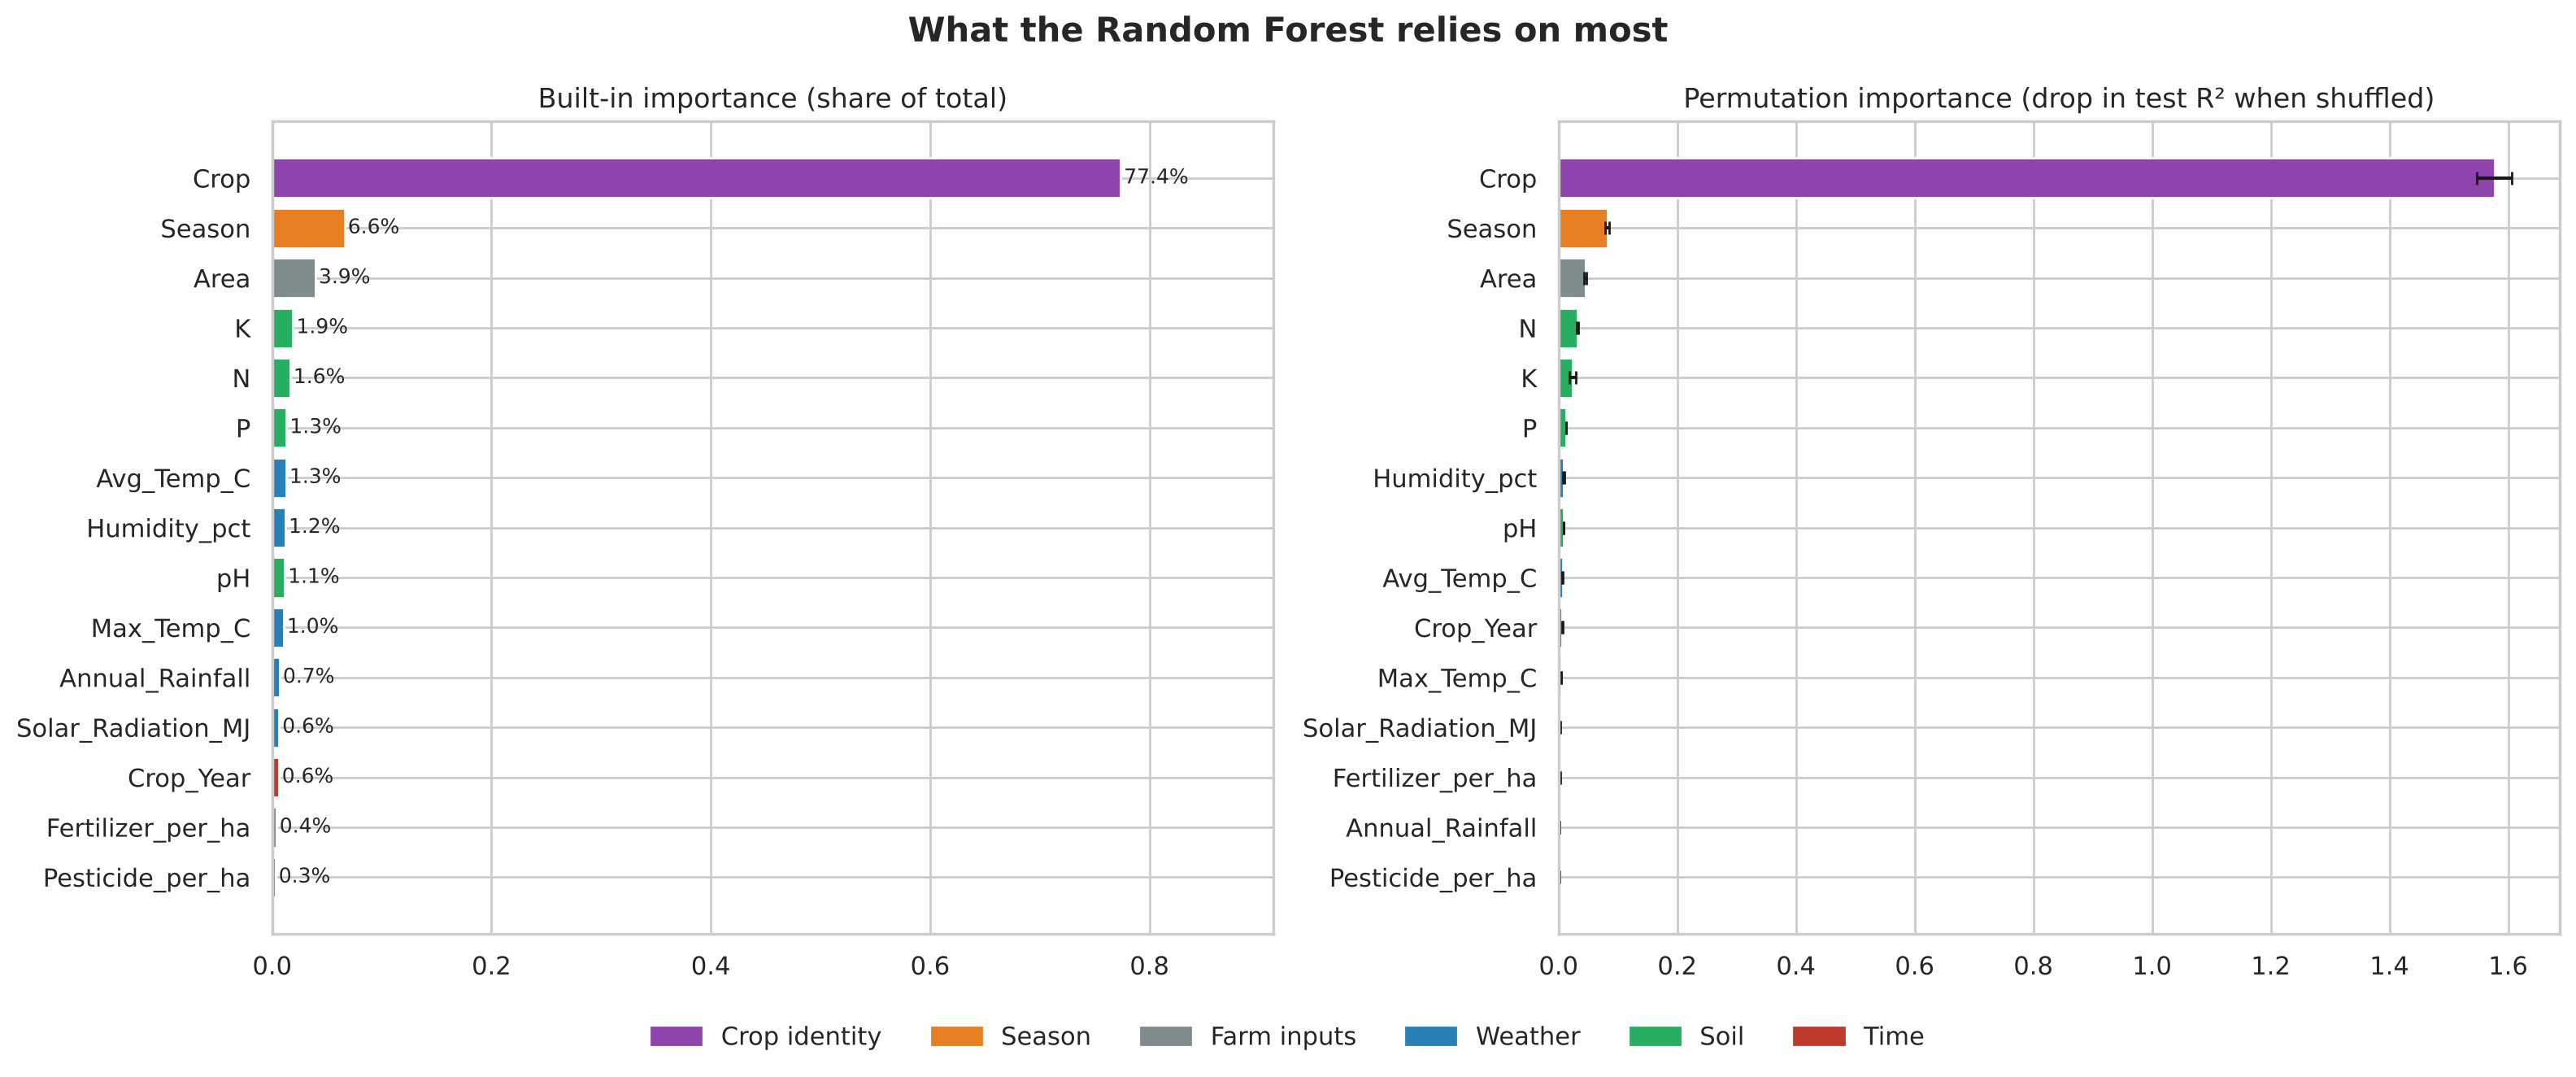

In [25]:
GROUP = {"Crop": "Crop identity", "Season": "Season", "Area": "Farm inputs", "Fertilizer_per_ha": "Farm inputs",
         "Pesticide_per_ha": "Farm inputs", "Annual_Rainfall": "Weather", "Avg_Temp_C": "Weather", "Max_Temp_C": "Weather",
         "Humidity_pct": "Weather", "Solar_Radiation_MJ": "Weather", "N": "Soil", "P": "Soil", "K": "Soil", "pH": "Soil",
         "Crop_Year": "Time"}
PALETTE = {"Crop identity": "#8e44ad", "Season": "#e67e22", "Farm inputs": "#7f8c8d", "Weather": "#2980b9",
           "Soil": "#27ae60", "Time": "#c0392b"}

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
imp = impurity.sort_values()
ax[0].barh(imp.index, imp.values, color=[PALETTE[GROUP[f]] for f in imp.index])
for i, v in enumerate(imp.values):
    ax[0].text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=9)
ax[0].set_title("Built-in importance (share of total)"); ax[0].set_xlim(0, imp.max() * 1.18)

pm = permutation["mean"].sort_values()
ax[1].barh(pm.index, pm.values, xerr=permutation.loc[pm.index, "std"], capsize=3,
           color=[PALETTE[GROUP[f]] for f in pm.index])
ax[1].set_title("Permutation importance (drop in test R² when shuffled)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE.values()]
fig.legend(handles, PALETTE.keys(), loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.suptitle(f"What the {final_name} relies on most", fontsize=15, fontweight="bold")
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig("outputs/feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

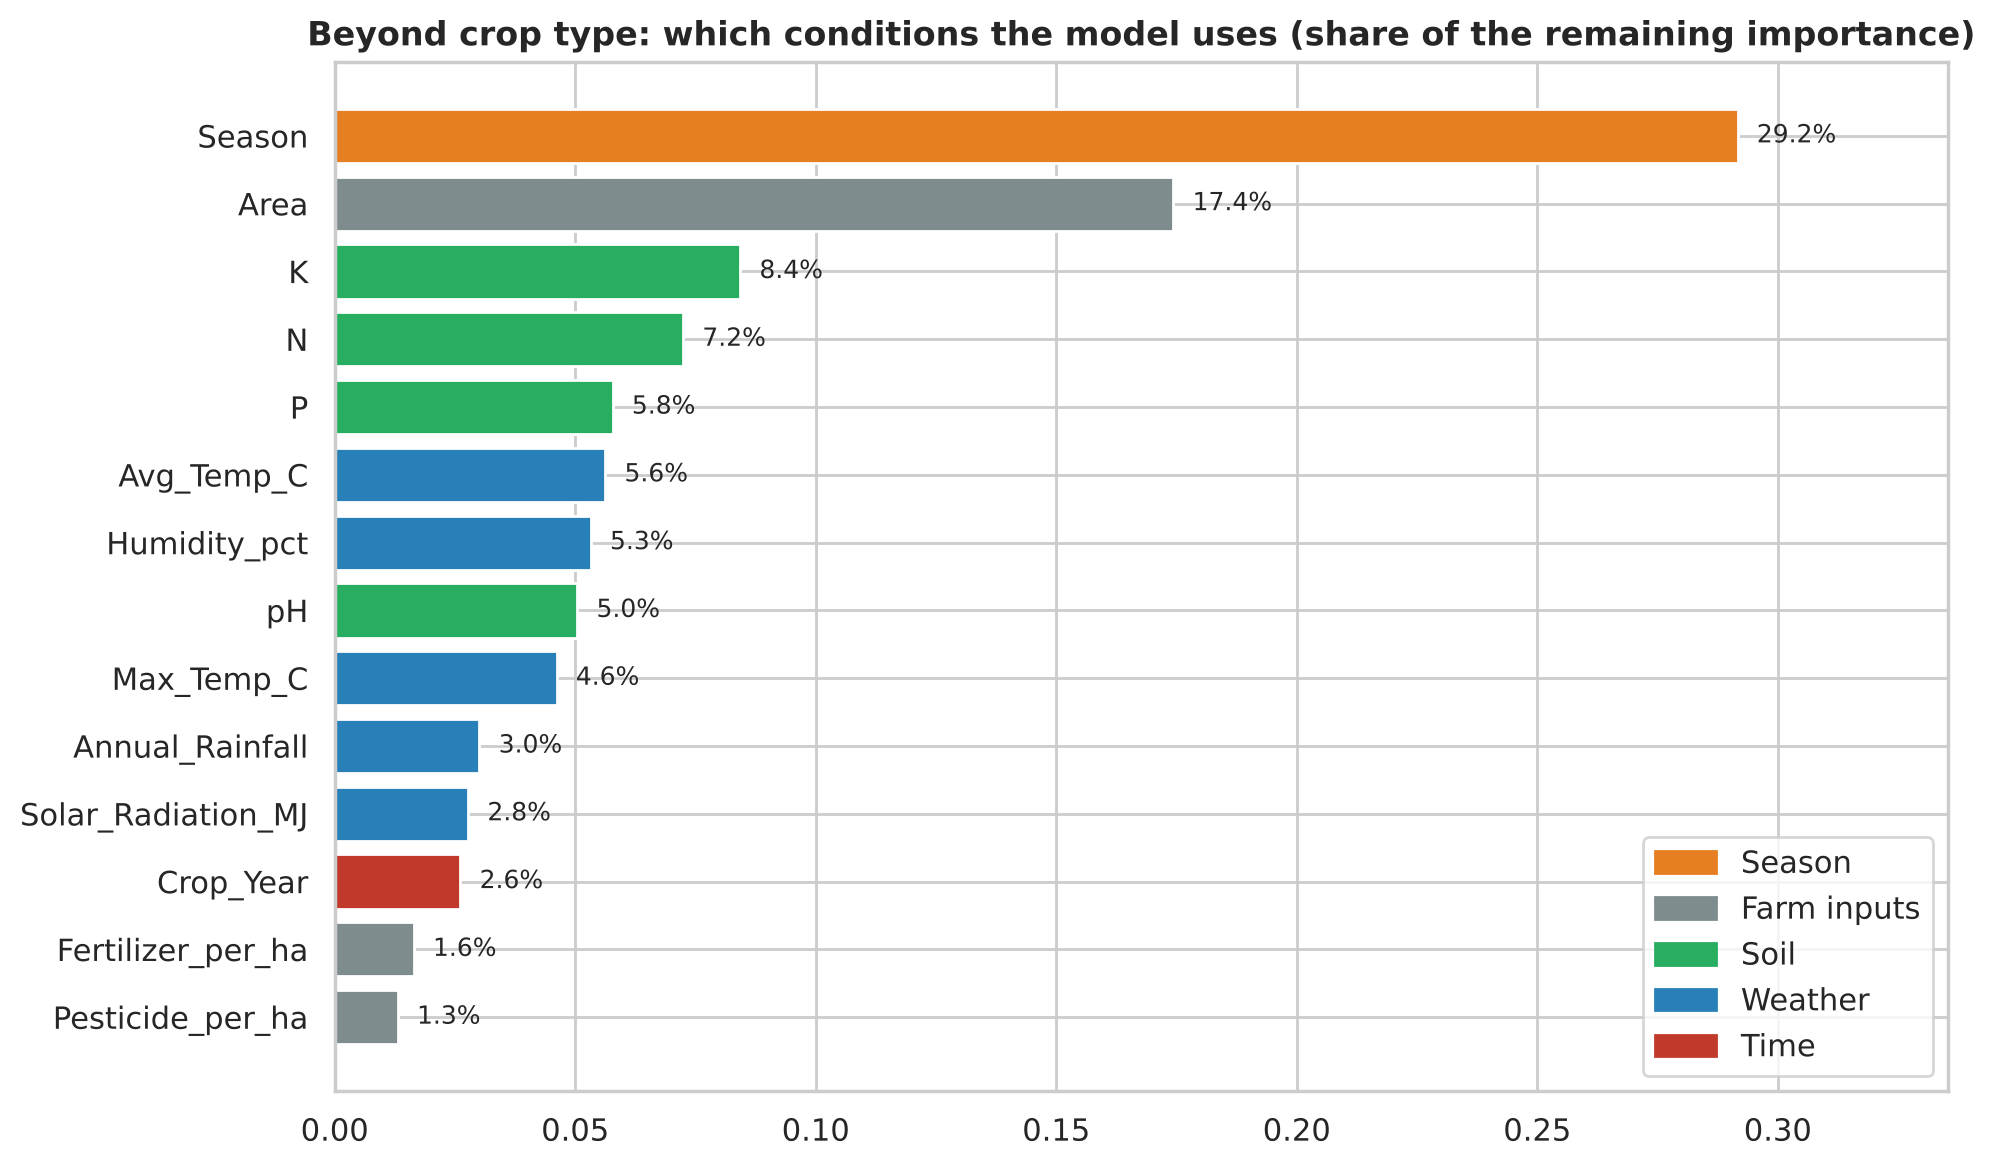

In [26]:
# Zoom in: everything except crop type, so the soil and weather inputs are readable
rest = impurity.drop("Crop")
rest = (rest / rest.sum()).sort_values()
plt.figure(figsize=(10, 6))
bars = plt.barh(rest.index, rest.values, color=[PALETTE[GROUP[f]] for f in rest.index])
for i, v in enumerate(rest.values):
    plt.text(v + 0.004, i, f"{v:.1%}", va="center", fontsize=9)
plt.xlim(0, rest.max() * 1.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[g]) for g in ["Season", "Farm inputs", "Soil", "Weather", "Time"]]
plt.legend(handles, ["Season", "Farm inputs", "Soil", "Weather", "Time"], loc="lower right")
plt.title("Beyond crop type: which conditions the model uses (share of the remaining importance)", fontweight="bold")
plt.tight_layout(); plt.savefig("outputs/feature_importance_zoom.png", dpi=150); plt.show()

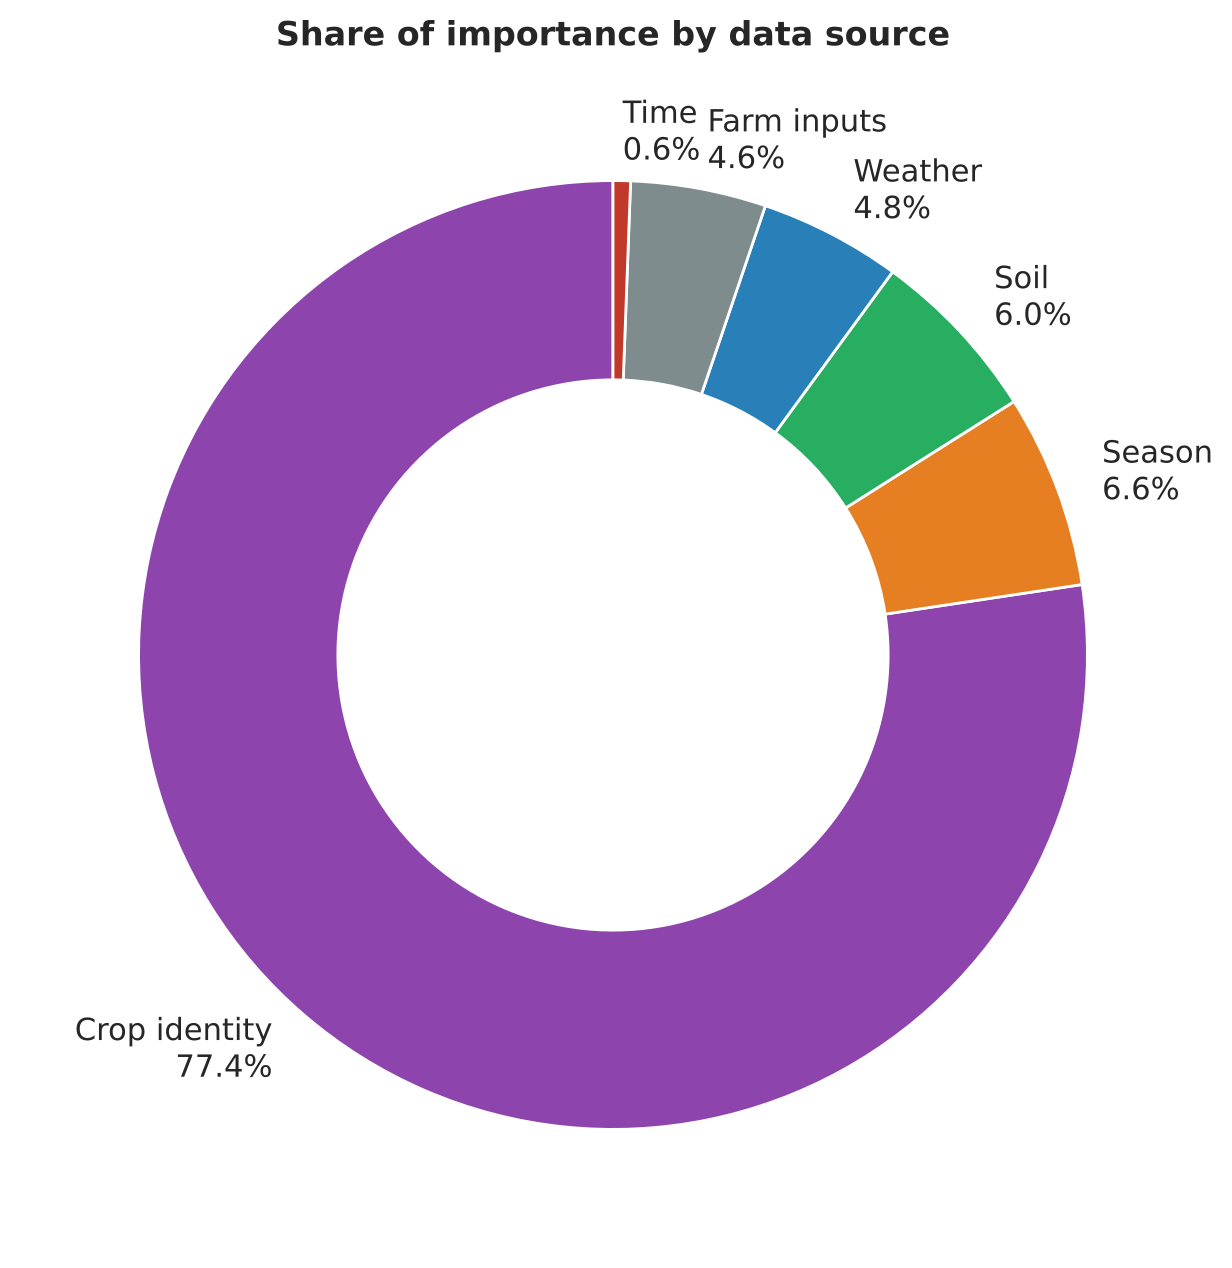

Crop identity    0.7737
Season           0.0660
Soil             0.0599
Weather          0.0483
Farm inputs      0.0461
Time             0.0059
dtype: float64

In [27]:
# Importance by data source (built-in importance summed per group)
by_group = impurity.groupby(lambda f: GROUP[f]).sum().sort_values(ascending=False)
plt.figure(figsize=(6.5, 6.5))
plt.pie(by_group.values, labels=[f"{g}\n{v:.1%}" for g, v in by_group.items()],
        colors=[PALETTE[g] for g in by_group.index], startangle=90, wedgeprops={"width": 0.42, "edgecolor": "white"})
plt.title("Share of importance by data source", fontweight="bold")
plt.tight_layout(); plt.savefig("outputs/importance_by_group.png", dpi=150); plt.show()
by_group.round(4)

**How to read it:** the **crop** decides the scale of the yield (sugarcane vs pulses), so it dominates. After that the model uses
**soil nutrients and weather**, which describe *where* the crop is grown, plus **season** and **farm inputs**.
Soil values are state averages and weather is one value per state per year, so they mainly tell the model about the growing region and year;
they are not farm-level measurements.

## 12. Predicting future years
A random split mixes years. A tougher, realistic test is to train only on **1997–2016** and predict **2017–2020**.

In [28]:
train_mask = df["Crop_Year"] <= 2016
time_pipe = clone(final_pipe).fit(X[train_mask], y[train_mask])
future_pred = time_pipe.predict(X[~train_mask])
print(f"Trained on {train_mask.sum()} records (1997–2016), tested on {(~train_mask).sum()} records (2017–2020)")
print(f"Future-years R²  : {r2_score(y[~train_mask], future_pred):.4f}")
print(f"Future-years MAE : {mean_absolute_error(y[~train_mask], future_pred):.4f} (log scale)")
summary["future_r2"] = r2_score(y[~train_mask], future_pred)
json.dump(summary, open("outputs/summary.json", "w"), indent=2)

Trained on 16440 records (1997–2016), tested on 3249 records (2017–2020)
Future-years R²  : 0.9507
Future-years MAE : 0.1420 (log scale)


## 13. Save the model

In [29]:
final_model = clone(final_pipe).fit(X, y)          # retrain on all data

state_profiles = (df.groupby("State")[["N", "P", "K", "pH", "Annual_Rainfall", "Avg_Temp_C", "Max_Temp_C",
                                        "Humidity_pct", "Solar_Radiation_MJ"]].median().round(2))
history = df.groupby(["Crop", "State"])["Yield"].median().round(3)   # typical real yield for comparison in the app
os.makedirs("models", exist_ok=True)
joblib.dump({"model": final_model, "model_name": final_name, "features": FEATURES,
             "state_profiles": state_profiles, "history": history,
             "crops": sorted(df["Crop"].unique()), "seasons": sorted(df["Season"].unique()),
             "fert_median": round(df["Fertilizer_per_ha"].median(), 1), "pest_median": round(df["Pesticide_per_ha"].median(), 2)},
            "models/crop_yield_model.joblib", compress=3)
print("Saved models/crop_yield_model.joblib (", round(os.path.getsize("models/crop_yield_model.joblib") / 1e6, 1), "MB )")

Saved models/crop_yield_model.joblib ( 71.1 MB )


## 14. Prediction function with a confidence range
A Random Forest is a vote of many trees. The **middle (median) tree answer** is used as the estimate, and the spread of the
trees' answers gives an **80% range** (10th–90th percentile), a simple way to show how certain the model is. The median is used
because a few trees can give extreme answers that would pull an average outside the range.

In [30]:
def predict_with_range(model, row):
    Xt = model.named_steps["preprocess"].transform(row)
    trees = np.array([t.predict(Xt) for t in model.named_steps["model"].estimators_])[:, 0]
    low, mid, high = np.percentile(trees, [10, 50, 90])        # median tree = estimate, 10th-90th = range
    return float(np.expm1(mid)), float(np.expm1(low)), float(np.expm1(high))

def predict_crop_yield(crop, season, state, year, area, fert_per_ha, pest_per_ha,
                       N=None, P=None, K=None, pH=None, rainfall=None, temp=None, max_temp=None, humidity=None, solar=None):
    p = state_profiles.loc[state]
    row = pd.DataFrame([{
        "Crop": crop, "Season": season, "Area": float(area), "Crop_Year": int(year),
        "Annual_Rainfall": rainfall if rainfall is not None else p["Annual_Rainfall"],
        "Fertilizer_per_ha": float(fert_per_ha), "Pesticide_per_ha": float(pest_per_ha),
        "N": N if N is not None else p["N"], "P": P if P is not None else p["P"],
        "K": K if K is not None else p["K"], "pH": pH if pH is not None else p["pH"],
        "Avg_Temp_C": temp if temp is not None else p["Avg_Temp_C"],
        "Max_Temp_C": max_temp if max_temp is not None else p["Max_Temp_C"],
        "Humidity_pct": humidity if humidity is not None else p["Humidity_pct"],
        "Solar_Radiation_MJ": solar if solar is not None else p["Solar_Radiation_MJ"],
    }])[FEATURES]
    est, low, high = predict_with_range(final_model, row)
    unit = "nuts" if crop == "Coconut" else "tonnes"
    hist = history.get((crop, state))
    return {"yield_per_ha": round(est, 3), "range_80": (round(low, 3), round(high, 3)), "unit": unit,
            "production": round(est * float(area), 1), "typical_real_yield_in_state": hist}

print(predict_crop_yield("Rice", "Kharif", "Punjab", 2020, area=1000, fert_per_ha=170, pest_per_ha=0.33))
print(predict_crop_yield("Wheat", "Rabi", "Uttar Pradesh", 2020, area=1000, fert_per_ha=170, pest_per_ha=0.33))

{'yield_per_ha': 3.749, 'range_80': (2.847, 4.067), 'unit': 'tonnes', 'production': 3749.5, 'typical_real_yield_in_state': np.float64(3.821)}
{'yield_per_ha': 4.281, 'range_80': (0.724, 4.44), 'unit': 'tonnes', 'production': 4281.4, 'typical_real_yield_in_state': np.float64(2.767)}


In [31]:
# What-if: same Punjab rice farm with more or less nitrogen in the soil
for n in [60, 100, 150]:
    r = predict_crop_yield("Rice", "Kharif", "Punjab", 2020, 1000, 170, 0.33, N=n)
    print(f"N = {n:3d} -> {r['yield_per_ha']:.2f} t/ha  (80% range {r['range_80'][0]:.2f}–{r['range_80'][1]:.2f})")

N =  60 -> 2.20 t/ha  (80% range 0.88–3.73)
N = 100 -> 3.23 t/ha  (80% range 2.38–3.92)
N = 150 -> 3.75 t/ha  (80% range 2.85–4.07)


In [32]:
# Sanity check on real records: Punjab rice, 2016–2020 (these were in the training data, so this checks the pipeline end to end)
sample = df[(df["Crop"] == "Rice") & (df["State"] == "Punjab") & (df["Crop_Year"] >= 2016)].copy()
sample["Predicted_Yield"] = np.expm1(final_model.predict(sample[FEATURES])).round(3)
sample["Error_%"] = ((sample["Predicted_Yield"] - sample["Yield"]) / sample["Yield"] * 100).round(1)
sample[["Crop", "State", "Season", "Crop_Year", "N", "Avg_Temp_C", "Humidity_pct", "Yield", "Predicted_Yield", "Error_%"]]

,Crop,State,Season,Crop_Year,N,Avg_Temp_C,Humidity_pct,Yield,Predicted_Yield,Error_%
15142,Rice,Punjab,Kharif,2016,150,24.42,63.26,4.066818,3.972,-2.3
15794,Rice,Punjab,Kharif,2017,150,23.62,64.26,4.252727,4.145,-2.5
16422,Rice,Punjab,Kharif,2018,150,23.22,66.39,4.011818,4.000,-0.3
17097,Rice,Punjab,Kharif,2019,150,22.69,69.01,3.930909,3.989,1.5


## 15. Gradio app
The full app with tabs (prediction, model comparison, feature importance, data) is in **`app.py`** — run it with
**Run App.bat** or `python app.py`. The cell below launches the same app from the notebook.

In [ ]:
import importlib, app as crop_app
importlib.reload(crop_app)
crop_app.demo.launch(inbrowser=True)

## 16. Conclusion and model card
**Results**
* The synthetic, formula-based data was replaced with **19,689 real crop records**, enriched with **soil nutrients (N, P, K, pH)**
  and **year-by-year weather from the Open-Meteo API** (temperature, max temperature, humidity, solar radiation).
* Five models were compared in the same pipeline. **Random Forest** was the most accurate on cross-validation, the test set
  and in original units. A tuning search was run; it did not beat the default settings on the test set, so those were kept.
* The feature-group study shows that describing each state by its **soil and weather** scores about the same as using the state name,
  which makes the model explainable and lets the app respond to soil and weather inputs.
* The feature-importance charts show the model relies most on **crop type**, then **soil, weather and season**.
* Predicting unseen future years (2017–2020) is harder than a random split, so real-world accuracy is somewhat lower than the test score.

**Model card**

| | |
|---|---|
| **Task** | Predict crop yield per hectare (and total production) for Indian states |
| **Model** | Random Forest regressor in a scikit-learn pipeline (one-hot + scaling), trained on log(1 + yield) |
| **Inputs** | Crop, season, year, area, rainfall, fertilizer/ha, pesticide/ha, soil N, P, K, pH, avg/max temperature, humidity, solar radiation |
| **Training data** | 1997–2020 state-level records (data sources in section 1) |
| **Evaluation** | 5-fold CV, 20% hold-out test set, and a train-on-1997–2016 / test-on-2017–2020 check |
| **Intended use** | Education and decision support: comparing crops, states and scenarios |
| **Limitations** | State-level averages, not farm measurements; soil is one value per state; weather is taken at one point per state; fertilizer and pesticide rates are national yearly averages in the source data; years after 2020 are extrapolation |